> **[OUTLINE] How to use this outline. Delete this cell before submission.**
>
> - The headings are the final report structure. Text in `[square brackets]` is a placeholder. Every block that starts with **[OUTLINE]** is a note for the team: search the notebook for `[OUTLINE]` and delete all of them before exporting.
> - Code cells hold starter code that follows our accepted game plan and the lecture notebooks (`Spark_DataFrame_API`, `Spark_SQL_API`). Lines marked `TODO` need something only we can supply (for example, the dataset folder on Jojie). Check every output against the data before writing about it.
> - **Test on a sample first, then start the full run early.** Set `DEV_ROW_LIMIT = 200_000` in Section 4.2 and run all cells. Then set it to `None` and run again. The raw file is one 42 GB CSV that must be read with `multiLine=True`, which Spark cannot split, so the staging pass (Section 4.5) runs on **one core** and can take an hour or more. Later sections read the staged Parquet table in parallel and are much faster.
> - Figure and table numbers are already assigned in order of appearance. If you add or remove one, renumber its caption and every reference to it.
>
> **Where each rubric requirement is met** (the target is *Excellent* everywhere):
>
> | Rubric component | What *Excellent* requires | Where |
> |---|---|---|
> | Title | Succinctly reflects what the study is about | Title cell |
> | Abstract | All five parts: context, problem statement, methodology, results, recommendation | Abstract |
> | Problem Statement | Explicit, succinct, clear, a single sentence or question, **in the introduction** | 1.2 |
> | Motivation | Explicit and convincing, **in the introduction** | 1.3 |
> | Data source | High-level description **and** how the source collected the data, for **every** dataset (also the file we exclude) | 2.1–2.3 |
> | Methodology Overview | Complete, explicit pipeline overview **with a diagram** | 3.1, Figure 1 |
> | Methodology Overview Details | High-level but specific to our problem (would not fit an unrelated problem) | 3.1 |
> | Methodology Details | Enough detail in the main text for a peer to reproduce the results | 3.2–3.4, 4–9 |
> | Results and Discussion (×2) | Interesting insights, all backed by the results | Discussion after every figure/table, 10 |
> | Conclusion (×2) | Answer to the problem stated explicitly, clearly, and accurately | 11 |
> | Recommendations (×2) | Limitations and future work discussed in detail | 12 |
> | References | Every source cited in-text, with an APA-formatted reference list | Throughout, 13 |
> | Organization | Logical paragraphs, sections, and headers that ease navigation | Table of Contents with links, numbered sections |
> | Aesthetics | Creative, professional visualizations that strongly integrate with the text | Shared style (4.1); every figure is discussed right after it |
> | Figures, Tables, and Equations | All labeled, with self-contained captions, and referred to in the text | All captions, Equations 1–3 |
> | Mechanics | No grammar or spelling errors; easy to digest | Final proofread (checklist) |
> | Data Exploration (×3) | Raw data described properly, with simple but relevant statistics for **all** raw data | 2.2, 5 (Table 7 profiles all 24 columns) |
> | Correctness of Methodology (×3) | Methodology correctly and completely addresses the problem | 3, 7–9 |
> | Execution of Methodology (×3) | Completely and properly executed | 4–9, all outputs kept |
> | Data Filtering (×3) | Every step detailed and justified, with the number **and** proportion of rows after each step | 6.3 (Table 13), 7.2, 9.1 |
> | Handling of Null Values (×3) | Detailed and justified, and done **only after investigating why** the nulls exist | 6.1, then 6.2 |
> | Accuracy and Mastery (×3) | No errors in facts or concepts; mastery shown | 3.2–3.3, all discussions |
> | Integration of Learnings (×3) | Techniques from the lectures **and beyond** | 3.3 (Table 4) |
> | Design Constraints (×3) | Extensive justifications **and alternative assumptions explored** | 3.3 (Table 3), 7.5, 8.4, 9.3 |
> | Answer to the problem (×3) | Answer completely and conclusively derived from the results | 10.1, 11 |
> | Significance and Impact (×3) | Actionable insights **beyond** the context of the study | 10.3, 12.1 |
> | PEP8 Compliance | All code clearly PEP8 compliant | All code (checklist) |
> | Code documentation | Every function and piece of code has a docstring or meaningful one-line comment | All code |
> | Nomenclature and Readability | Consistent, intelligible names | All code |
> | Dataset, Format, Executability, Anonymity | Listed dataset; descriptive analytics; raw input 16–50 GB; `du -sch` screenshot; all files except data; runs top to bottom; author not identifiable | 4.3, checklist below |
>
> **Before you submit**
>
> - [ ] `DEV_ROW_LIMIT = None`, then *Kernel → Restart Kernel and Run All Cells*; every cell ran, no errors, all outputs kept.
> - [ ] Terminal screenshot of `du -sch` on **the file** `all_reviews.csv` (about 40G; not the whole folder, which also holds the excluded file) saved as `figures/du_sch_raw_data.png`. Hide your username first, e.g. run `export PS1='$ '` before `du -sch`.
> - [ ] HTML export: `jupyter nbconvert --to html <notebook>.ipynb`. Figures shown by code cells are embedded automatically.
> - [ ] Submit: this notebook, its HTML export, `make_pipeline_diagram.py`, and the `figures/` folder. Do **not** submit `scratch/` (processed data) or any raw data. Delete `scratch/` on Jojie after the final run.
> - [ ] Anonymity: no names, student numbers, SLT name, or usernames anywhere (notebook, HTML, file names, file paths, screenshot). Search the HTML for your usernames.
> - [ ] PEP8: `jupyter nbconvert --to script <notebook>.ipynb`, then `pycodestyle <notebook>.py`. Fix everything except `E402` (imports placed in later cells).
> - [ ] Every `[OUTLINE]` note, `[placeholder]`, and `TODO` removed. Figures and tables numbered consecutively, each referred to in the text.
> - [ ] Every in-text citation is in Section 13 and every reference is cited (APA 7th edition).

# Player Dissatisfaction in Steam Reviews: What Patterns Characterize Negative Recommendations?

### A Descriptive Analysis of [113.9] Million Steam Reviews with Apache Spark

> **[OUTLINE] Title** (rubric: *succinctly reflects what the study is all about*). This is the title of our accepted game plan. Keep it, or once results are in, consider a sharper one that states the main finding, e.g. "[Main finding]: Patterns of Negative Recommendations in 113.9 Million Steam Reviews". Update the review count in the subtitle after Section 6 (use the cleaned count if you prefer). No names, student numbers, or SLT name anywhere.

## Abstract

> **[OUTLINE]** Write this last, as one paragraph of 200–250 words. The rubric checks for all five parts below, so draft them as five labeled sentences or pairs of sentences, then remove the labels.
> 1. **Context:** Steam user reviews are the most visible public record of player satisfaction, but a game's overall score does not show where negative recommendations concentrate or what they complain about.
> 2. **Problem statement:** the main question from Section 1.2, word for word.
> 3. **Methodology:** Apache Spark (DataFrame, SQL, and ML APIs) on the 42 GB `all_reviews.csv` (113,883,717 raw reviews); the cleaning steps and the number of reviews kept; the negative-recommendation share by game, playtime band, review year, and language; the term ratio on English reviews.
> 4. **Results:** one or two headline numbers per research question.
> 5. **Recommendation:** the most actionable recommendation from Section 12.1, plus the main limitation.

[Context.] [Problem statement.] [Data and methodology.] [Results for RQ1.] [Results for RQ2.] [Results for RQ3.] [Recommendation and main limitation.]

## Table of Contents

1. [Introduction](#introduction)
    1. [Background](#background)
    2. [Problem Statement](#problem-statement)
    3. [Motivation](#motivation)
    4. [Scope and Report Structure](#scope)
2. [Data Source and Description](#data-source)
3. [Methodology](#methodology)
4. [Data Loading and Staging](#data-loading)
5. [Exploratory Data Analysis](#eda)
6. [Data Cleaning and Filtering](#cleaning)
7. [Games with the Highest Share of Negative Recommendations (RQ1)](#rq1)
8. [Negative Recommendations by Playtime, Year, and Language (RQ2)](#rq2)
9. [Words that Characterize Negative English Reviews (RQ3)](#rq3)
10. [Results and Discussion](#results)
11. [Conclusion](#conclusion)
12. [Recommendations](#recommendations)
13. [References](#references)

[Appendix A. Reproducibility and Supplementary Files](#appendix-a)

<a id="introduction"></a>
## 1. Introduction

<a id="background"></a>
### 1.1 Background

Steam, the digital distribution platform run by Valve Corporation, is one of the most popular places to buy and play PC games (Lin et al., 2019). In 2023, the year in which our data ends, it passed 33 million concurrent users for the first time (Valve Corporation, 2024). Any Steam user who has recorded playtime on a game can review it. Each review must state whether the reviewer recommends the game, and it can explain why in free text. Steam then combines the positive and negative reviews into the review score shown on the game's store page (Valve Corporation, n.d.-c).

These reviews matter beyond the opinion of a single player. Lin et al. (2019) note that reviews can decide a game's commercial fate, because potential buyers often base their purchasing decisions on them. Research on online retail points the same way. An improvement in a product's reviews raises its sales relative to competing sellers, and one-star reviews affect sales more strongly than five-star reviews do (Chevalier & Mayzlin, 2006). Negative reviews are also the most informative for developers, since they contain more of the complaints and bug reports that show what players dislike (Lin et al., 2019).

A review score, however, summarizes one game at one moment. It does not show where negative recommendations concentrate across the catalog. Which games draw the largest shares of them? Which kinds of reviewers are most dissatisfied? How has dissatisfaction changed over the years, and does it differ between language communities? What do dissatisfied players write about? Answering these questions requires examining all reviews together. The dataset used in this report holds 113,883,717 Steam reviews in a single 42 GB CSV file (KieranPO'C, 2023), too large to process comfortably in the memory of one machine with pandas. We therefore use Apache Spark, a unified engine for large-scale data processing, through its DataFrame, SQL, and machine-learning interfaces (Armbrust et al., 2015; Zaharia et al., 2016).

This report is descriptive. It measures how often reviews do not recommend a game and compares that share across games, reviewer groups, and words. It does not predict reviews or claim that any factor causes dissatisfaction.

<a id="problem-statement"></a>
### 1.2 Problem Statement

**What patterns characterize player dissatisfaction in Steam reviews?**

In this report, dissatisfaction is measured by negative recommendations: reviews in which the reviewer does not recommend the game (`voted_up` is false). We answer the main question through three research questions, each looking at dissatisfaction from a different angle:

1. **RQ1 (which games).** Which games with at least 1,000 reviews have the highest shares of negative recommendations? (Section 7)
2. **RQ2 (which reviewers).** How does the negative-recommendation share differ by playtime at review, review year, and review language? (Section 8)
3. **RQ3 (which complaints).** Which words appear far more often in negative English reviews than in positive ones? (Section 9)

<a id="motivation"></a>
### 1.3 Motivation

Negative recommendations have direct consequences for a game. Steam computes the review score from the balance of positive and negative reviews. A game whose score falls below 40%, into the *Mostly Negative* range, becomes less likely to be featured by Steam's recommendation algorithms (Valve Corporation, n.d.-c). Buyers also rely on reviews when deciding what to purchase (Chevalier & Mayzlin, 2006; Lin et al., 2019). Knowing where dissatisfaction concentrates is therefore useful to several groups:

- **Game developers** can see which situations go together with negative recommendations, such as the first hours of play, and which complaints recur across many games, and so decide what to fix first.
- **Publishers and community managers** can see which language communities are the most negative, which is where responses and localized support may be most needed.
- **Platforms such as Steam** can monitor dissatisfaction across the whole catalog and over time, not one game at a time.
- **Players, journalists, and researchers** get a factual description of the whole catalog that complements single-game reviews and earlier studies of smaller samples (Lin et al., 2019).

A descriptive analysis of all the reviews suits this problem for three reasons:

- **Patterns must be described before they can be explained.** Knowing which games, reviewer groups, and words stand out is the first step toward any study of why players are dissatisfied.
- **Scale matters.** Many games receive few reviews, so a sample would leave them unmeasured. A 1% sample, for instance, would leave a game with 1,000 reviews about 10. Analyzing all 113.9 million reviews keeps every game with at least 1,000 reviews and every major language in view.
- **The method is reproducible.** The pipeline uses only Spark's built-in functions and one public dataset. It can be rerun on a newer snapshot or applied to reviews from another platform.

<a id="scope"></a>
### 1.4 Scope and Report Structure

This report analyzes one file, `all_reviews.csv` from Version 2 (10 December 2023) of the dataset, which covers all games and languages in that snapshot. It adds no outside data, and it never uses or displays reviewer IDs. Its findings describe the reviews in this snapshot only. Because reviewers choose to write reviews, the results cannot show how all players feel or why any of them were dissatisfied.

The rest of the report is organized as follows. Section 2 describes the data source, and Section 3 the methodology and its design constraints. Sections 4 to 6 load, explore, and clean the data. Sections 7 to 9 answer RQ1 to RQ3 in turn, and Sections 10 to 12 discuss the results, state the conclusion, and give recommendations.

<a id="data-source"></a>
## 2. Data Source and Description

### 2.1 Source and Collection

The data is Version 2 (10 December 2023) of *100 Million+ Steam Reviews*, a dataset published on Kaggle by KieranPO'C (2023). This report reads the copy in the course's shared data folder on Jojie (Section 4). The data was collected in two stages:

- **By Steam.** A Steam user who has recorded playtime on a game can write a review that either recommends or does not recommend it, with free text explaining why (Valve Corporation, n.d.-c). Steam attaches metadata that it records itself. This includes the reviewer's playtime in the game (in total, in the last two weeks, and when the review was written), the language the reviewer chose, and creation and update timestamps. It also includes whether the game was bought on Steam or received for free, whether the review was written during Early Access, and how many users rated the review as helpful or funny (Valve Corporation, n.d.-a, n.d.-d).
- **By the dataset author.** According to the dataset description, the reviews were collected from Steam's *User Reviews – Get List* API (KieranPO'C, 2023). This public endpoint returns the reviews of one game at a time, in pages, with the fields listed in Table 2 (Valve Corporation, n.d.-d). By default, it leaves out reviews that Steam has flagged as off-topic activity ("review bombs") unless the caller asks to include them (Valve Corporation, n.d.-d). The endpoint returns reviews without the game's name, so the dataset author must have added the `game` column separately.

The data contains no reviewer names. Reviewers appear only as numeric Steam IDs, which this report drops during staging (Section 4.5) and never displays.

Table 1 lists the two files of the dataset. Only `all_reviews.csv` is analyzed. The second file, `weighted_score_above_08.csv`, is a filtered subset of the same reviews that, as its name indicates, keeps reviews with a weighted vote score above 0.8. Including it would count those reviews twice.

**Table 1.** Files in Version 2 of the dataset and their role in this report.

| File | Contents | Size | Used |
|---|---|---|---|
| `all_reviews/all_reviews.csv` | All 113,883,717 reviews, one row per review, 24 columns | 42,487,005,552 bytes (40G by `du -sch`) | Yes: the only input |
| `weighted_score_above_08.csv` | Subset of the same reviews with a weighted vote score above 0.8 | 699 MB | No: it would count the same reviews twice |

### 2.2 Fields

All 24 columns are stored as text, under a header row. A CSV field that contains commas, quotes, or line breaks, as review text often does, must be enclosed in double quotes (Shafranovich, 2005). This shapes how the file is read (Section 4.4). Table 2 describes every column, following the Steamworks documentation of the reviews API (Valve Corporation, n.d.-a, n.d.-d), and states its role in this report.

**Table 2.** Columns of `all_reviews.csv`, in file order, with their meaning and their use in this report. Playtimes are in minutes and timestamps in Unix seconds (UTC).

| # | Column | Description | Use in this report |
|---|---|---|---|
| 1 | `recommendationid` | Unique ID of the review | Key; duplicates removed (Section 6) |
| 2 | `appid` | Steam application ID of the reviewed game | RQ1 key |
| 3 | `game` | Name of the game, added by the dataset author | RQ1 labels |
| 4 | `author_steamid` | Reviewer's Steam ID | Not used, for privacy (Section 3.3) |
| 5 | `author_num_games_owned` | Number of games the reviewer owns | Exploration only |
| 6 | `author_num_reviews` | Number of public reviews the reviewer has written | Exploration only |
| 7 | `author_playtime_forever` | Reviewer's lifetime playtime in the game | Exploration only |
| 8 | `author_playtime_last_two_weeks` | Reviewer's playtime in the two weeks before collection | Exploration only |
| 9 | `author_playtime_at_review` | Reviewer's playtime when the review was written | RQ2 playtime bands |
| 10 | `author_last_played` | When the reviewer last played the game | Exploration only |
| 11 | `language` | Language the reviewer chose for the review | RQ2; RQ3 filter |
| 12 | `review` | Review text | RQ3 |
| 13 | `timestamp_created` | When the review was created | RQ2 review year |
| 14 | `timestamp_updated` | When the review was last updated | Choosing among duplicate rows |
| 15 | `voted_up` | True if the reviewer recommends the game | Outcome for all RQs |
| 16 | `votes_up` | Number of users who found the review helpful | Exploration only |
| 17 | `votes_funny` | Number of users who found the review funny | Exploration only |
| 18 | `weighted_vote_score` | Steam's helpfulness score for the review | Exploration only |
| 19 | `comment_count` | Number of comments on the review | Exploration only |
| 20 | `steam_purchase` | True if the reviewer bought the game on Steam | Exploration only |
| 21 | `received_for_free` | True if the reviewer marked the game as received for free | Exploration only |
| 22 | `written_during_early_access` | True if the review was written while the game was in Early Access | Exploration only |
| 23 | `hidden_in_steam_china` | Flag returned by the API for Steam China; not described further in the documentation | Exploration only |
| 24 | `steam_china_location` | Location field returned by the API for Steam China; not described further in the documentation | Exploration only |

### 2.3 Known Limitations of the Source

Four properties of the source limit what the data can show. Section 12.2 returns to them.

- **Reviewers select themselves.** Only players who chose to write a review are included, so every share in this report describes reviewers, not all players.
- **Only players with recorded playtime can review.** Reviews therefore come from people who launched the game through Steam (Valve Corporation, n.d.-c). Playtime counts only time tracked by the Steam client.
- **Some reviews may be missing.** Unless the dataset author changed the API's default, reviews flagged as off-topic review bombs are not included (Valve Corporation, n.d.-d). Reviews deleted before December 2023 are absent, and edits made after collection are not reflected.
- **Our shares are not Steam's review scores.** Steam's score counts only reviews from accounts that purchased the game, not key activations (Valve Corporation, n.d.-c). This report counts every review in the file, so its negative shares need not match the scores shown on store pages.

<a id="methodology"></a>
## 3. Methodology

### 3.1 Pipeline Overview

Figure 1 summarizes the methodology as eight steps in three stages. Below the figure, each step is described and linked to the section where it is carried out.

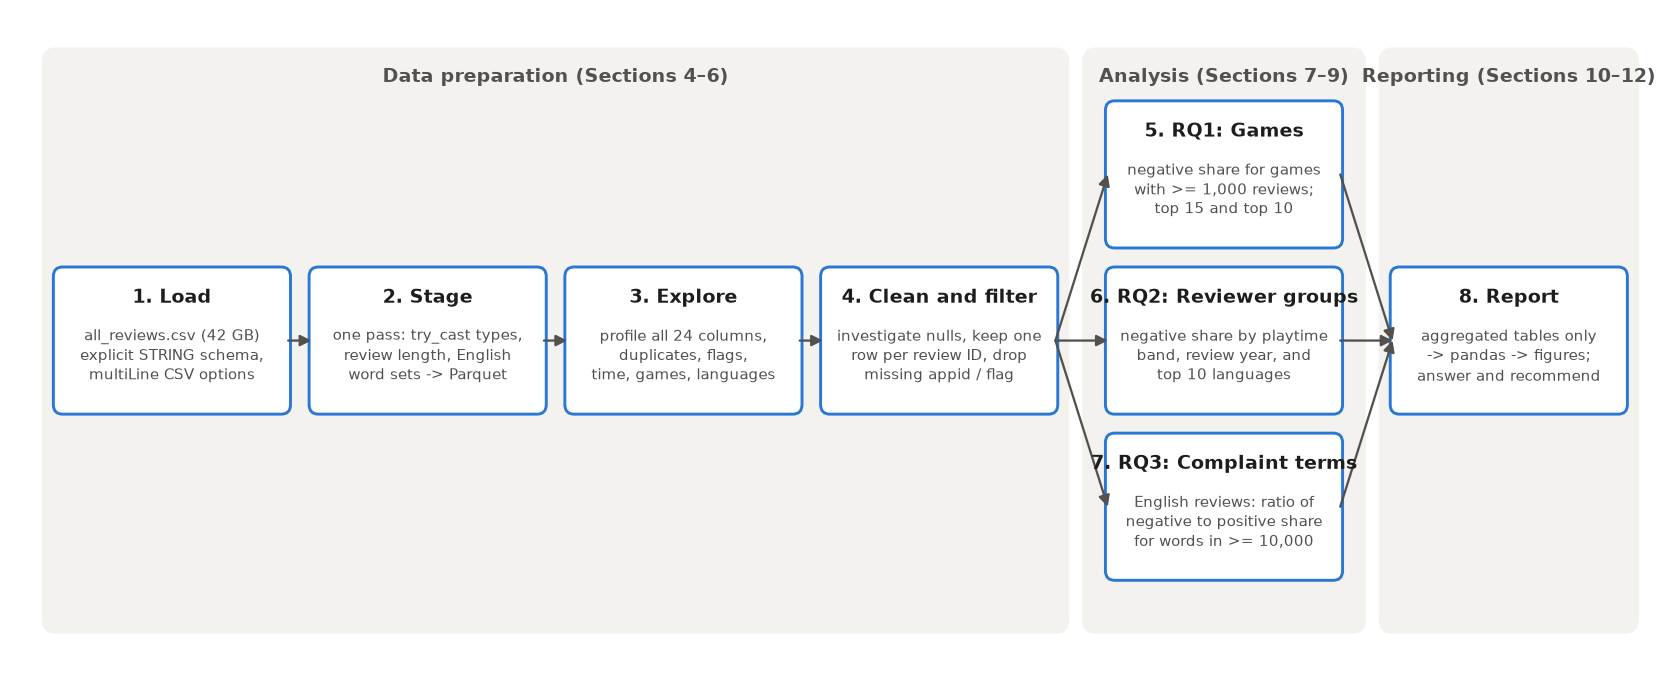

In [1]:
import os

from IPython.display import Image, display

# Figure 1 is drawn by the supplementary script make_pipeline_diagram.py
from make_pipeline_diagram import draw_pipeline

os.makedirs('figures', exist_ok=True)
PIPELINE_FIGURE = os.path.join('figures', 'pipeline_overview.png')
draw_pipeline(PIPELINE_FIGURE)
display(Image(PIPELINE_FIGURE, width=950))

**Figure 1.** The eight steps of the methodology, grouped into data preparation, analysis, and reporting. Steps 1–2 read the 42 GB raw file once and stage a compact typed table; steps 3–4 explore and clean it; steps 5–7 answer RQ1–RQ3 in Spark; and only aggregated tables reach pandas in step 8. The supplementary script `make_pipeline_diagram.py` draws this figure.

1. **Load (Section 4).** Read `all_reviews.csv` in place on Jojie with an explicit schema that types every column as `STRING`, and CSV options for quoted, multi-line review text.
2. **Stage (Section 4.5).** In a single pass over the raw file, convert each numeric column with `try_cast`, record values that fail to convert, measure review length, split each English review into its set of distinct content words with Spark ML, and write the result to a scratch Parquet table. The review text and reviewer IDs are not kept.
3. **Explore (Section 5).** Profile all 24 raw columns, and examine duplicates, flag encodings, time coverage, games, languages, playtime, and review length.
4. **Clean and filter (Section 6).** Investigate why values are missing, then keep valid review IDs, keep one row per review ID, and drop rows without a game ID or a recommendation flag, logging the count and proportion kept after each step.
5. **RQ1 (Section 7).** Compute the negative-recommendation share (Equation 1) for each game with at least 1,000 retained reviews; rank the top 15 by share, with 95% Wilson intervals (Equation 2), and the top 10 by number of negative reviews.
6. **RQ2 (Section 8).** Compute the same share for five playtime-at-review bands, each review year, and the 10 most common languages, both pooled and averaged over games.
7. **RQ3 (Section 9).** For English reviews, compute how much more often each word appears in negative than in positive reviews (Equation 3) and report the 20 highest ratios among words found in at least 10,000 reviews.
8. **Report (Sections 10–12).** Move only aggregated tables to pandas, plot them, and turn them into answers, a conclusion, and recommendations.

Sections 7.5, 8.4, and 9.3 repeat steps 5–7 under alternative assumptions to test how robust the findings are.

### 3.2 Definitions

The analysis uses three measures, defined once here and referred to by their equation numbers in the rest of the report.

**Negative-recommendation share.** For any group $g$ of retained reviews (a game, a playtime band, a year, or a language),

$$s_g = \frac{n^{-}_{g}}{n_g}, \tag{1}$$

where $n_g$ is the number of retained reviews in $g$ and $n^{-}_{g}$ the number of those with `voted_up` false. The overall share $s$ uses all retained reviews and appears as a reference line in Figures 7 and 9–11.

**Uncertainty of a share.** A share computed from few reviews is unstable, so each game's share in Section 7 carries a 95% Wilson score interval (Wilson, 1927),

$$\frac{1}{1 + z^2/n_g}\left(s_g + \frac{z^2}{2n_g} \pm z\sqrt{\frac{s_g(1 - s_g)}{n_g} + \frac{z^2}{4n_g^2}}\right), \qquad z = 1.96. \tag{2}$$

**Playtime bands.** Playtime at review is converted from minutes to hours and grouped into the bands of the game plan: under 1 h, 1–10 h, 10–50 h, 50–200 h, and 200+ h. Each band includes its lower bound and excludes its upper bound. Reviews with missing playtime form a separate *Unknown* band.

**Review year.** The calendar year of `timestamp_created` in UTC. The final year is labeled *partial* if the last review in the file was created before 31 December.

**Term ratio.** Among English reviews with at least one content word, let $N^{-}$ and $N^{+}$ be the numbers of negative and positive reviews, and $d^{-}_{w}$ and $d^{+}_{w}$ the numbers of negative and positive reviews that contain word $w$ at least once. The term ratio is

$$r_w = \frac{d^{-}_{w} / N^{-}}{d^{+}_{w} / N^{+}}, \tag{3}$$

so $r_w = 3$ means that a negative review is three times as likely as a positive review to contain $w$. Only words with $d^{-}_{w} + d^{+}_{w} \geq 10{,}000$ are ranked, so that ratios are not driven by rare words.

### 3.3 Design Constraints and Choices

Processing 42 GB of quoted, multi-line text on one shared server imposes constraints that shaped every step of the pipeline. Table 3 lists each constraint, the choice made, its justification, and the alternative considered. The main alternatives are tested with data in Sections 4.4, 7.5, 8.4, and 9.3.

**Table 3.** Design constraints, the choices made, their justification, and the alternatives considered.

| Constraint | Choice | Justification | Alternative considered |
|---|---|---|---|
| One 42 GB CSV whose review text contains commas, quotes, and line breaks | `multiLine=True`, `quote='"'`, `escape='"'` | A field with line breaks or quotes is enclosed in double quotes, and a quote inside it is doubled (Shafranovich, 2005). `multiLine` lets one record span several lines, and `escape='"'` replaces Spark's default backslash escape (Apache Software Foundation, n.d.-a). | Reading without `multiLine` splits the file into many partitions, but every line break inside a review starts a broken record: [fill: records without multiLine, Table 6] records instead of [fill: reviews read, Table 6]. |
| A file read with `multiLine` cannot be split, so each scan of it runs on one core | Scan the raw file **once** and stage a compact Parquet table (Section 4.5) | Parquet is columnar and splittable, so later steps read only the columns they need, in parallel (lecture: *Working with Parquet files*). Staging took [fill: minutes, Table 21]; later queries take seconds to minutes. | Persisting the raw DataFrame (lecture: *Persistence*) would need about 40 GB of memory or disk, and it is lost whenever the kernel restarts. |
| Unknown encodings and possibly malformed values | Read every column as `STRING`, convert with `try_cast`, and count the values that fail | Separates *missing* values from *malformed* ones (Section 6.1). Under ANSI mode, the default since Spark 4.0, a plain cast of a malformed value stops the job with an error (Apache Software Foundation, n.d.-c). | `inferSchema` needs an extra pass over all 42 GB (lecture: *Spark DataFrame*) and still cannot report malformed values. |
| Storage on Jojie, and the instruction not to copy raw data | The staged table keeps typed fields, review length, and English word sets only. It drops the review text and reviewer IDs, lives in `scratch/`, is deleted after the final run, and is never submitted. | Keeps intermediate storage at [fill: size from `du -sh scratch`], far below the 40 GB raw file. | Staging the full text would take nearly as much space as the raw file. |
| Driver memory | Only aggregated tables move to pandas, through Arrow (lecture: *Spark DataFrame and pandas*) | The 113.9 million review-level rows would not fit in the driver's memory. | `toPandas()` on review-level data. |
| Duplicate review IDs | Keep the most recently updated row per ID, chosen with a window function | Deterministic, and keeps the reviewer's latest version of the review. | `dropDuplicates()` keeps an arbitrary row. |
| Shares of games with few reviews are unstable | At least 1,000 reviews per game, plus Wilson intervals (Equation 2) | Prevents games with a 100% share from a handful of reviews from topping the ranking. | 500 and 5,000 reviews, and ranking by the interval's lower bound (Section 7.5). |
| Pooled shares are dominated by a few heavily reviewed games | Also report game-averaged shares | Shows whether a group pattern holds across games or comes from a few large ones. | Section 8.4. |
| Rare words give extreme ratios | Words in at least 10,000 reviews | Stable ratios with enough evidence behind each. | 2,000 and 50,000 reviews (Section 9.3). |
| Reproducible review years | Session time zone set to UTC | Unix timestamps convert to the same year on any machine. | The server's local time zone would shift reviews written near midnight on 31 December into the wrong year. |
| Python UDFs are slow, since each row is serialized to Python | Built-in Spark SQL functions and Spark ML transformers only | Work stays in Spark's JVM (lecture: *User-defined functions*). | Python or pandas UDFs. |
| Privacy and anonymity | Reviewer IDs are dropped during staging and never shown; paths contain no usernames | Required by the instructions and the game plan. | None. |

Table 4 maps each technique to the section where it is used and states whether it was covered in the lectures.

**Table 4.** Techniques used, where they appear, and whether they come from the lectures or go beyond them.

| Technique | Section | Source |
|---|---|---|
| `SparkSession` in local mode with all cores; Arrow for `toPandas()` | 4.1 | Lecture: Spark DataFrame API |
| Explicit DDL schema instead of `inferSchema` | 4.4 | Lecture: Spark DataFrame API |
| Parquet staging, column pruning, `explain()` | 4.5 | Lecture: Spark DataFrame API |
| `groupBy` and `agg`, `filter`, `explode`, regular expressions | 5–9 | Lecture: Spark DataFrame API |
| Temporary views and `spark.sql` queries | 6.4, 7, 9 | Lecture: Spark SQL API |
| Persistence of a small, reused aggregate | 5.6 | Lecture: Spark DataFrame API |
| CSV options for multi-line, quoted text; `try_cast`; `percentile_approx`; `approx_count_distinct` | 4–5 | Beyond: Spark documentation (Apache Software Foundation, n.d.-a) |
| Window functions for deterministic de-duplication | 6.3 | Beyond |
| Spark ML `RegexTokenizer` and `StopWordsRemover`; `Bucketizer` | 4.5, 5.8 | Beyond (Apache Software Foundation, n.d.-b) |
| Wilson score intervals; game-averaged shares; sensitivity analysis | 7–9 | Beyond: statistics |

### 3.4 Tools and Environment

The analysis runs on Jojie, the course's JupyterLab server, with Apache Spark [fill: version printed in Section 4.1] in local mode on [fill: cores printed in Section 4.1] cores and 16 GB of driver memory. PySpark provides the DataFrame, SQL, and ML interfaces. pandas and NumPy handle the small aggregated tables, and matplotlib draws the figures. Figure 1 is drawn by the supplementary script `make_pipeline_diagram.py`. Appendix A lists the software versions and the runtime of each expensive step (Table 21). The single staging pass over the raw file takes most of the total runtime (Table 3).

<a id="data-loading"></a>
## 4. Data Loading and Staging

This section prepares the data in five steps. It starts Spark and fixes the parameters of the game plan (Sections 4.1 and 4.2), confirms the size of the raw input (Section 4.3), reads the CSV with an explicit schema (Section 4.4), and stages it once as a compact Parquet table (Section 4.5). The raw file is read in place from the shared folder on Jojie, so no data file is copied or submitted with this report.

### 4.1 Libraries, Plotting Style, and Spark Session

In [2]:
import csv
import os
import subprocess
import sys
import time
import warnings
from contextlib import contextmanager
from functools import reduce

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter, PercentFormatter
from pyspark.ml.feature import Bucketizer, RegexTokenizer, StopWordsRemover
from pyspark.sql import SparkSession, Window
from pyspark.sql import functions as F

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 60)

# One plotting style for every figure (same palette as our Lab 1 report)
PRIMARY = '#2a78d6'  # data marks
ACCENT = '#eb6834'   # highlighted marks, e.g. a partial year
MUTED = '#52514e'    # reference lines and annotations
plt.rcParams.update({
    'figure.figsize': (8, 4.5),
    'figure.dpi': 110,
    'font.size': 10,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.titlelocation': 'left',
    'axes.labelcolor': MUTED,
    'axes.edgecolor': '#b5b4ae',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'axes.axisbelow': True,
    'grid.color': '#e6e5e0',
    'grid.linewidth': 0.8,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
})

# Wall-clock time of the expensive steps, reported in Appendix A
RUNTIMES = {}


@contextmanager
def timed(label):
    """Measure the wall-clock time of a block and store it in RUNTIMES.

    Parameters
    ----------
    label : str
        Name of the step, used as the key in ``RUNTIMES``.
    """
    start = time.perf_counter()
    yield
    RUNTIMES[label] = time.perf_counter() - start
    print(f'{label}: {RUNTIMES[label] / 60:.1f} min')

Spark runs in local mode (`local[*]`), so a single JVM on the Jojie server uses every available core, as in the course notebooks. Five settings differ from Spark's defaults, for the reasons given in Table 3:

- **Arrow** speeds up the conversion of Spark results to pandas, which the report uses only for small aggregated tables (lecture: *Spark DataFrame and pandas*).
- **The UTC time zone** makes Unix timestamps convert to the same calendar year on any machine.
- **Disabled progress bars** keep Spark's job progress messages out of the report's cell outputs.
- **16 GB of driver memory.** In local mode, the driver also runs every task, and the de-duplication in Section 6.4 sorts more than 100 million rows. With Spark's default of 1 GB, it would spill to disk constantly.
- **400 shuffle partitions**, twice Spark's default of 200, keep each partition of the largest shuffle small enough to sort in memory.

### 4.2 Paths and Analysis Parameters

The next cell defines every threshold of the game plan once, so that all sections use the same values, and it lists the alternatives tested in Sections 7.5, 8.4, and 9.3 next to them. `DEV_ROW_LIMIT` reads only the first rows of the file. This made it possible to test the whole notebook in minutes before the full run, and it is `None` in the final run. The two intermediate tables are written to a `scratch` folder, which is deleted after the final run and never submitted.

In [3]:
# Raw input, read in place on Jojie and never copied.
# TODO: replace [FOLDER] with the dataset folder from our game plan. Also
# check whether a copy exists under /mnt/localdata/public, which is faster.
RAW_DIR = '/mnt/data/public/[FOLDER]/all_reviews'
RAW_FILE = os.path.join(RAW_DIR, 'all_reviews.csv')

# Development switch: read only the first N reviews to test the notebook
# quickly (e.g. 200_000). Must be None for the final run.
DEV_ROW_LIMIT = None

# Intermediate Parquet tables (processed data): never submitted, and
# deleted after the final run
SCRATCH_DIR = 'scratch'
RUN_TAG = f'dev{DEV_ROW_LIMIT}' if DEV_ROW_LIMIT else 'full'
STAGED_PATH = os.path.join(SCRATCH_DIR, f'reviews_staged_{RUN_TAG}.parquet')
CLEAN_PATH = os.path.join(SCRATCH_DIR, f'reviews_clean_{RUN_TAG}.parquet')
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

# Analysis parameters fixed in the accepted game plan
MIN_GAME_REVIEWS = 1_000   # RQ1: minimum retained reviews per game
TOP_GAMES_BY_SHARE = 15    # RQ1: games ranked by negative share
TOP_GAMES_BY_COUNT = 10    # RQ1: games ranked by negative reviews
TOP_LANGUAGES = 10         # RQ2: most common review languages
MIN_TERM_REVIEWS = 10_000  # RQ3: reviews that must contain a word
TOP_TERMS = 20             # RQ3: words ranked by term ratio

# Playtime-at-review bands: (lower bound in hours, inclusive; label)
PLAYTIME_BANDS = [
    (0, 'Under 1 h'),
    (1, '1–10 h'),
    (10, '10–50 h'),
    (50, '50–200 h'),
    (200, '200+ h'),
]
UNKNOWN_BAND = 'Unknown'
BAND_ORDER = [label for _, label in PLAYTIME_BANDS] + [UNKNOWN_BAND]

# Alternative assumptions explored in Sections 7.5, 8.4, and 9.3
GAME_THRESHOLDS = [500, 1_000, 5_000]
MIN_GAME_REVIEWS_PER_GROUP = 100
TERM_THRESHOLDS = [2_000, 10_000, 50_000]

### 4.3 Raw Input Size

The raw input must be between 16 and 50 GB. The next cell measures `all_reviews.csv` with `du -sch`, and Figure 2 shows the same command run in a terminal.

In [4]:
def show_disk_usage(path):
    """Print the output of ``du -sch`` for a file or folder.

    Parameters
    ----------
    path : str
        File or folder to measure.
    """
    result = subprocess.run(['du', '-sch', path], capture_output=True,
                            text=True, check=True)
    print(result.stdout)


show_disk_usage(RAW_FILE)

# Terminal screenshot required by the submission instructions
DU_SCREENSHOT = os.path.join(FIG_DIR, 'du_sch_raw_data.png')
if os.path.exists(DU_SCREENSHOT):
    display(Image(DU_SCREENSHOT, width=600))
else:
    print(f'TODO: save the terminal screenshot as {DU_SCREENSHOT}')

CalledProcessError: Command '['du', '-sch', '/mnt/data/public/[FOLDER]/all_reviews/all_reviews.csv']' returned non-zero exit status 1.

**Figure 2.** Terminal output of `du -sch` on the raw input, `all_reviews.csv`. The file occupies 40G (42,487,005,552 bytes), within the required 16–50 GB. It is the only raw file that the notebook reads.

### 4.4 Reading the CSV with an Explicit Schema

The file is read with an explicit schema instead of `inferSchema`, which would need an extra pass over all 42 GB just to guess the column types (lecture: *Spark DataFrame*). Three decisions define how it is read:

- **The header is checked first.** When a schema is supplied, Spark applies it to the columns by position and ignores the header line (Apache Software Foundation, n.d.-a). A difference in column order would therefore mislabel columns without any error, so the first cell below compares the header with the 24 names of Table 2 before reading.
- **Every column is read as `STRING`.** Types are assigned in Section 4.5 with `try_cast`, which returns null for a value that cannot be converted. As a result, a malformed value is counted (Table 7) instead of silently becoming null or, under the ANSI mode that Spark 4 enables by default, stopping the job with an error (Apache Software Foundation, n.d.-c).
- **The CSV options match how review text is stored.** A field containing commas, line breaks, or quotes is enclosed in double quotes, and a quote inside the field is written twice (Shafranovich, 2005). `multiLine=True` lets one record span several lines, and `escape='"'` replaces Spark's default backslash escape with the doubled quote (Apache Software Foundation, n.d.-a). `mode='PERMISSIVE'` keeps a record that cannot be parsed completely and sets its unparsable fields to null, so that any problem surfaces in Section 5 instead of stopping the read.

In [ ]:
# Columns of all_reviews.csv in file order (Table 2)
RAW_COLUMNS = [
    'recommendationid', 'appid', 'game', 'author_steamid',
    'author_num_games_owned', 'author_num_reviews',
    'author_playtime_forever', 'author_playtime_last_two_weeks',
    'author_playtime_at_review', 'author_last_played', 'language',
    'review', 'timestamp_created', 'timestamp_updated', 'voted_up',
    'votes_up', 'votes_funny', 'weighted_vote_score', 'comment_count',
    'steam_purchase', 'received_for_free', 'written_during_early_access',
    'hidden_in_steam_china', 'steam_china_location',
]

# Check the header line before reading: Spark would otherwise apply our
# names to the columns by position without complaint
with open(RAW_FILE, encoding='utf-8', newline='') as raw_csv:
    header = next(csv.reader(raw_csv))
print(f'{len(header)} columns in the header')
assert header == RAW_COLUMNS, f'Update RAW_COLUMNS to match: {header}'

In [ ]:
# Every column is read as text; Section 4.5 assigns the real types
RAW_SCHEMA = ', '.join(f'`{name}` STRING' for name in RAW_COLUMNS)

raw_reviews = spark.read.csv(
    RAW_FILE,
    schema=RAW_SCHEMA,
    header=True,
    multiLine=True,    # review text can contain line breaks
    quote='"',
    escape='"',        # quotes inside text are doubled ("") as in RFC 4180
    mode='PERMISSIVE',
)
if DEV_ROW_LIMIT:
    raw_reviews = raw_reviews.limit(DEV_ROW_LIMIT)

n_raw_partitions = raw_reviews.rdd.getNumPartitions()
print(f'Partitions of the raw CSV: {n_raw_partitions}')

In [ ]:
# Design check (Table 3): the same file read without multiLine. Spark can
# split it into many partitions, but a line break inside a review then
# starts a new, broken record. Skipped in development runs, which read
# only the first rows of the file.
n_single_line_partitions, n_single_line_rows = None, None
if DEV_ROW_LIMIT is None:
    single_line = spark.read.csv(RAW_FILE, schema=RAW_SCHEMA, header=True,
                                 quote='"', escape='"', mode='PERMISSIVE')
    n_single_line_partitions = single_line.rdd.getNumPartitions()
    with timed('Count records without multiLine (parallel)'):
        n_single_line_rows = single_line.count()
    print(f'Without multiLine: {n_single_line_partitions} partitions, '
          f'{n_single_line_rows:,} records')

With `multiLine=True`, the raw CSV is read as [fill: partitions of the raw CSV, printed above] partition. A file read this way cannot be split: because a review may contain line breaks, Spark cannot tell where a record starts without parsing the file from its beginning. The whole 42 GB file is therefore processed by a single task on one core. Read without `multiLine`, the same file splits into [fill: partitions without multiLine, printed above] partitions that are processed in parallel, but every line break inside a review then starts a new record, which inflates the row count (Table 6). Correct records matter more than parallelism, so the report keeps `multiLine=True` and limits the cost of the single-core read by scanning the file only once (Section 4.5).

### 4.5 Staging a Typed Parquet Table

Because every scan of the raw file runs on one core, the notebook reads it only once and writes the result to a compact Parquet table in the scratch folder. Parquet stores data by column and can be split, so every later step reads only the columns it needs, in parallel on all cores (lecture: *Working with Parquet files*). The single pass does five things:

1. It converts the 14 numeric columns with `try_cast`, to `BIGINT` for IDs, counts, and timestamps and to `DOUBLE` for playtimes and the helpfulness score.
2. It records, in a list column `cast_failures`, the name of every numeric column whose non-empty raw value could not be converted.
3. It replaces the review text with its length and the reviewer's Steam ID with a flag recording whether one was present, as committed in the game plan.
4. For English reviews only, it tokenizes the text and keeps the set of distinct content words (Section 9.1). Doing this here avoids a second single-core pass over the raw text for RQ3.
5. It keeps the eight text and flag columns as raw strings. The flags are converted in Section 6, after their encodings are examined (Section 5.4).

Dropping the review text and reviewer IDs keeps the staged table at [fill: size from `du -sh scratch`], compared with 40 GB for the raw file. The staging pass took [fill: minutes, Table 21]. If the staged table already exists, the cell reuses it instead of reading the raw file again.

In [ ]:
# Numeric raw columns and the type each one is converted to
NUMERIC_TYPES = {
    'recommendationid': 'BIGINT',
    'appid': 'BIGINT',
    'author_num_games_owned': 'BIGINT',
    'author_num_reviews': 'BIGINT',
    'author_playtime_forever': 'DOUBLE',
    'author_playtime_last_two_weeks': 'DOUBLE',
    'author_playtime_at_review': 'DOUBLE',
    'author_last_played': 'BIGINT',
    'timestamp_created': 'BIGINT',
    'timestamp_updated': 'BIGINT',
    'votes_up': 'BIGINT',
    'votes_funny': 'BIGINT',
    'weighted_vote_score': 'DOUBLE',
    'comment_count': 'BIGINT',
}
# Text and flag columns, kept as raw strings; flags are converted in
# Section 6, after their encodings are examined in Section 5.4
TEXT_COLUMNS = [
    'game', 'language', 'voted_up', 'steam_purchase', 'received_for_free',
    'written_during_early_access', 'hidden_in_steam_china',
    'steam_china_location',
]


def try_cast(column, sql_type):
    """Convert a STRING column, giving null when a value does not parse.

    Parameters
    ----------
    column : str
        Name of a raw STRING column.
    sql_type : str
        Spark SQL type to convert to, such as ``'BIGINT'``.

    Returns
    -------
    pyspark.sql.Column
        The converted column.
    """
    return F.expr(f'try_cast(`{column}` AS {sql_type})')


# RQ3 tokenizer (Section 9.1): lowercase, split on anything that is not a
# letter, drop one-letter tokens, then remove Spark's English stop words
tokenizer = RegexTokenizer(inputCol='english_text', outputCol='tokens',
                           pattern='[^a-z]+', gaps=True, toLowercase=True,
                           minTokenLength=2)
stop_word_remover = StopWordsRemover(inputCol='tokens',
                                     outputCol='content_words')

# Only English reviews are tokenized; other rows get an empty string
english_text = F.when(F.col('language') == 'english',
                      F.coalesce(F.col('review'), F.lit(''))).otherwise('')

# Name of every numeric column whose non-null value failed to convert
cast_failures = F.filter(
    F.array(*[
        F.when(F.col(name).isNotNull() & try_cast(name, sql_type).isNull(),
               F.lit(name))
        for name, sql_type in NUMERIC_TYPES.items()
    ]),
    lambda name: name.isNotNull(),
)

staged = (
    stop_word_remover.transform(
        tokenizer.transform(
            raw_reviews.withColumn('english_text', english_text)))
    .select(
        *[try_cast(name, sql_type).alias(name)
          for name, sql_type in NUMERIC_TYPES.items()],
        *TEXT_COLUMNS,
        # Reviewer IDs are not kept, only whether one was present
        F.col('author_steamid').isNotNull().alias('has_author_steamid'),
        F.length('review').alias('review_length'),
        cast_failures.alias('cast_failures'),
        # Distinct content words of English reviews; null for other rows
        F.when(F.size('content_words') > 0,
               F.array_distinct('content_words')).alias('words'),
    )
)

if os.path.exists(STAGED_PATH):
    print(f'Reusing the staged table in {STAGED_PATH}')
else:
    with timed('Stage the raw CSV as Parquet (single pass)'):
        staged.write.parquet(STAGED_PATH, mode='overwrite')

reviews_staged = spark.read.parquet(STAGED_PATH)
reviews_staged.printSchema()

In [ ]:
# First rows of the staged table (no reviewer IDs or review text)
display(reviews_staged.limit(5).toPandas())

**Table 5.** First five rows of the staged table. Numeric columns are typed, flags are still raw strings, `cast_failures` lists the columns whose raw value could not be converted, and `words` holds the distinct content words of English reviews.

Table 5 shows that the staged table has the intended structure. IDs, counts, playtimes, and timestamps are numeric, the flags remain raw strings, and `words` is filled for English reviews only. Neither reviewer IDs nor review text appear in it.

<a id="eda"></a>
## 5. Exploratory Data Analysis

This section describes the raw data as staged in Section 4.5, before any cleaning, so that every decision in Section 6 rests on evidence. It first reports the size of the data and profiles all 24 raw columns (Sections 5.1 and 5.2). It then examines the properties the analysis depends on: duplicate review IDs, the encoding of the recommendation flag, when reviews were written, how reviews are spread across games and languages, playtime at review, and review text (Sections 5.3 to 5.9).

### 5.1 Size and Structure

In [ ]:
with timed('Count staged rows'):
    n_raw = reviews_staged.count()

display(pd.Series({
    'File': os.path.basename(RAW_FILE),
    'Size on disk (GB)': f'{os.path.getsize(RAW_FILE) / 1e9:,.1f}',
    'Columns in the raw file': len(RAW_COLUMNS),
    'Reviews (rows) read': f'{n_raw:,}',
    'Reviews in the game plan': '113,883,717',
    'Records if read without multiLine': (
        '–' if n_single_line_rows is None else f'{n_single_line_rows:,}'),
    'Partitions of the raw CSV': n_raw_partitions,
    'Partitions without multiLine': (
        '–' if n_single_line_partitions is None
        else n_single_line_partitions),
    'Partitions of the staged table':
        reviews_staged.rdd.getNumPartitions(),
}, name='value').to_frame())

**Table 6.** Size and structure of the raw input: the number of reviews read, the number of records Spark finds if the file is read without `multiLine` (Section 4.4), and the number of Spark partitions in each case and after staging.

The staged table holds [fill: reviews read] reviews in 24 raw columns, [fill: "exactly" or "N fewer than"] the 113,883,717 reviews reported for this file in our game plan. Read without `multiLine`, the same file yields [fill: records without multiLine] records, [fill: difference] more than the correct count. Each extra record is a fragment of a review that contains a line break, which confirms the reading choices of Section 4.4. The staged Parquet table, in contrast, is split into [fill: partitions of the staged table] partitions, so every query from this point on runs in parallel on all cores.

### 5.2 Profile of All Raw Columns

In [ ]:
def profile_columns(df):
    """Compute simple statistics for all 24 raw columns in one pass.

    Numeric columns get non-null count, approximate distinct count, min,
    approximate median, mean, and max. Text columns get non-null and
    approximate distinct counts. ``review`` is summarized by its length,
    and ``author_steamid`` only by how often it is present.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        The staged table.

    Returns
    -------
    pandas.DataFrame
        One row per raw column, in file order.
    """
    numeric = [(name, name) for name in NUMERIC_TYPES]
    numeric.append(('review', 'review_length'))
    aggregations = [F.count('*').alias('rows')]
    for raw_name, column in numeric:
        aggregations += [
            F.count(column).alias(f'{raw_name}:non-null'),
            F.approx_count_distinct(column).alias(f'{raw_name}:distinct'),
            F.min(column).alias(f'{raw_name}:min'),
            F.percentile_approx(column, 0.5).alias(f'{raw_name}:median'),
            F.mean(column).alias(f'{raw_name}:mean'),
            F.max(column).alias(f'{raw_name}:max'),
        ]
    for name in TEXT_COLUMNS:
        aggregations += [
            F.count(name).alias(f'{name}:non-null'),
            F.approx_count_distinct(name).alias(f'{name}:distinct'),
        ]
    aggregations.append(F.sum(F.col('has_author_steamid').cast('int'))
                        .alias('author_steamid:non-null'))

    stats = df.agg(*aggregations).first().asDict()
    n_rows = stats.pop('rows')
    table = {}
    for key, value in stats.items():
        column, statistic = key.split(':')
        table.setdefault(column, {})[statistic] = value
    profile = pd.DataFrame.from_dict(table, orient='index')
    profile.insert(1, 'missing %', 1 - profile['non-null'] / n_rows)
    return profile.reindex(RAW_COLUMNS)


with timed('Profile all raw columns'):
    column_profile = profile_columns(reviews_staged)

# Raw values that could not be converted to their numeric type
failed_casts = (reviews_staged
                .select(F.explode('cast_failures').alias('column'))
                .groupBy('column').count()
                .toPandas().set_index('column')['count'])
column_profile.insert(2, 'failed casts',
                      failed_casts.reindex(column_profile.index))
column_profile.loc[list(NUMERIC_TYPES), 'failed casts'] = (
    column_profile.loc[list(NUMERIC_TYPES), 'failed casts'].fillna(0))

display(column_profile.style.format({
    'non-null': '{:,.0f}', 'missing %': '{:.2%}', 'failed casts': '{:,.0f}',
    'distinct': '{:,.0f}', 'min': '{:,.4g}', 'median': '{:,.4g}',
    'mean': '{:,.4g}', 'max': '{:,.4g}',
}, na_rep='–'))

print(f'Values that failed to convert, all numeric columns: '
      f'{int(failed_casts.sum()):,}')

**Table 7.** Profile of all 24 raw columns, in file order: non-null values, share missing, values that could not be converted to their numeric type, approximate number of distinct values, and, for numeric columns, the minimum, approximate median, mean, and maximum. `review` is described by its length in characters and `author_steamid` only by how often it is present. Distinct counts and medians are approximate (`approx_count_distinct`, `percentile_approx`).

Table 7 gives simple statistics for every column of the raw file. Four observations shape the rest of the report:

- **The key fields are nearly complete.** [confirm] `recommendationid`, `appid`, and `voted_up` are missing in [fill]%, [fill]%, and [fill]% of rows. Section 6.1 investigates these rows before Section 6.3 removes them.
- **The file is parsed correctly.** [confirm] Across the 14 numeric columns, only [fill: total printed below the table] values could not be converted. A misread CSV would shift text into numeric columns and cause failed casts in many rows, so this small number shows that the options of Section 4.4 read the file as intended.
- **The units match the documentation.** The median playtime at review is [fill] minutes, about [fill] hours, consistent with playtimes recorded in minutes (Valve Corporation, n.d.-a). `timestamp_created` ranges from [fill: min] to [fill: max], which as Unix times in seconds correspond to [fill: year] and 2023.
- **Reviewer activity and helpfulness counts are highly skewed.** [confirm] For example, the median review has [fill] helpful votes (`votes_up`), while the maximum is [fill]. These columns describe how other users reacted to a review rather than the reviewer's own satisfaction, so the analysis does not use them (Table 2).

`author_steamid` is present in [fill]% of rows. As committed in the game plan, the IDs themselves were dropped during staging, so only this count is reported.

### 5.3 Duplicate Review IDs

In [ ]:
def copies_differ(column):
    """Flag groups whose rows hold different values of a column.

    Comparing the minimum with the maximum is cheaper than counting
    distinct values: several distinct counts in one aggregation make Spark
    copy every row once per column.

    Parameters
    ----------
    column : str
        Column to compare across the rows of each group.

    Returns
    -------
    pyspark.sql.Column
        1 if the values differ, 0 otherwise (nulls are ignored).
    """
    return (F.min(column) != F.max(column)).cast('int')


# One row per review ID, with whether its copies differ
copies = (reviews_staged
          .filter(F.col('recommendationid').isNotNull())
          .groupBy('recommendationid')
          .agg(F.count('*').alias('copies'),
               copies_differ('appid').alias('appids_differ'),
               copies_differ('voted_up').alias('flags_differ'),
               copies_differ('timestamp_updated').alias('updates_differ')))

duplicate_summary = (copies
                     .filter(F.col('copies') > 1)
                     .agg(F.count('*').alias('IDs with more than one row'),
                          F.sum(F.col('copies') - 1).alias('extra rows'),
                          F.max('copies').alias('most rows for one ID'),
                          F.sum('appids_differ')
                          .alias('IDs whose rows differ in appid'),
                          F.sum('flags_differ')
                          .alias('IDs whose rows differ in voted_up'),
                          F.sum('updates_differ')
                          .alias('IDs whose rows differ in update time'))
                     .toPandas().T.fillna(0))
duplicate_summary.columns = ['value']
display(duplicate_summary.style.format('{:,.0f}'))
extra_rows = int(duplicate_summary.loc['extra rows', 'value'])
print(f'Extra rows: {extra_rows:,} ({extra_rows / n_raw:.3%} of all rows)')

**Table 8.** Review IDs that appear in more than one row, and how their copies differ.

[fill: IDs with more than one row] review IDs appear in more than one row, adding [fill: extra rows] extra rows, or [fill: printed below the table]% of all rows. [confirm] Most of these copies differ only in `timestamp_updated`, which indicates that the same review was collected more than once, before and after the reviewer edited it. Counting every copy would give such reviews extra weight in every share. Section 6.3 therefore keeps one row per review ID: the most recently updated copy, which reflects the reviewer's latest opinion. [fill] IDs have copies with different recommendation flags, and keeping the latest copy resolves them in favor of the reviewer's current recommendation.

### 5.4 Recommendation and Other Flags

In [ ]:
FLAG_COLUMNS = [
    'voted_up', 'steam_purchase', 'received_for_free',
    'written_during_early_access', 'hidden_in_steam_china',
]


def value_counts(df, column):
    """Count every raw value of a column, including nulls.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Table to count.
    column : str
        Column whose values are counted.

    Returns
    -------
    pyspark.sql.DataFrame
        Columns ``column``, ``value``, and ``count``.
    """
    return (df.groupBy(F.col(column).alias('value')).count()
            .select(F.lit(column).alias('column'), 'value', 'count'))


flag_values = (reduce(lambda left, right: left.unionByName(right),
                      [value_counts(reviews_staged, name)
                       for name in FLAG_COLUMNS])
               .toPandas()
               .sort_values(['column', 'count'], ascending=[True, False]))
flag_values['share'] = (flag_values['count'] / flag_values
                        .groupby('column')['count'].transform('sum'))
display(flag_values.set_index(['column', 'value'])
        .style.format({'count': '{:,.0f}', 'share': '{:.2%}'}))

**Table 9.** Raw values of the five true/false columns, with their counts and shares. A missing value is shown as `None`.

Table 9 shows that `voted_up` is stored as [fill: e.g. `True` and `False`], which the conversion below recognizes through `TRUE_VALUES` and `FALSE_VALUES`. [fill] rows ([fill]%) have a missing or unrecognized value. They cannot be used, because the recommendation is the outcome of every research question. Among the other flags, [fill]% of reviews come from reviewers who bought the game on Steam, [fill]% were written during Early Access, and [fill]% were marked as received for free. [Use only if `steam_purchase` is never false: Every review comes from a Steam purchase, so reviews by players who obtained the game in other ways are absent from the data.]

In [ ]:
# Raw encodings of true and false observed in Table 9.
# TODO: confirm these against Table 8 and add any other encoding.
TRUE_VALUES = ['true', '1', '1.0']
FALSE_VALUES = ['false', '0', '0.0']


def to_bool(column):
    """Convert a raw true/false STRING column to BOOLEAN.

    Parameters
    ----------
    column : str
        Name of a raw flag column.

    Returns
    -------
    pyspark.sql.Column
        True or False for recognized values, and null for missing or
        unrecognized ones.
    """
    value = F.lower(F.trim(F.col(column)))
    return (F.when(value.isin(TRUE_VALUES), True)
            .when(value.isin(FALSE_VALUES), False))


raw_flags = (reviews_staged
             .select(to_bool('voted_up').alias('recommended'))
             .groupBy('recommended').count()
             .toPandas().set_index('recommended')['count'])
missing_flags = int(raw_flags[raw_flags.index.isna()].sum())
for name, count in [('Recommended', raw_flags.get(True, 0)),
                    ('Not recommended', raw_flags.get(False, 0)),
                    ('Missing or unrecognized', missing_flags)]:
    print(f'{name}: {count:,} ({count / n_raw:.2%} of raw reviews)')

After conversion, [fill]% of the raw reviews recommend the game and [fill]% do not, while [fill]% have a missing or unrecognized flag. Negative recommendations are therefore [confirm] a minority of reviews. The raw negative share of [fill]% is the baseline for interpreting Sections 7 and 8: a game or group well above it is unusually criticized.

### 5.5 When Reviews Were Written

In [ ]:
reviews_by_year = (reviews_staged
                   .groupBy(F.year(F.timestamp_seconds('timestamp_created'))
                            .alias('year'))
                   .count()
                   .toPandas()
                   .sort_values('year'))
first_review, last_review = (reviews_staged
                             .select(F.timestamp_seconds('timestamp_created')
                                     .alias('created'))
                             .agg(F.min('created'), F.max('created'))
                             .first())
no_year = reviews_by_year['year'].isna()
print(f'First review: {first_review} UTC; last review: {last_review} UTC')
print(f'Reviews without a valid creation time: '
      f'{reviews_by_year.loc[no_year, "count"].sum():,}')

In [ ]:
def format_count(value):
    """Format a count compactly, e.g. 1234567 becomes '1.2M'.

    Parameters
    ----------
    value : float
        Count to format.

    Returns
    -------
    str
        The formatted count.
    """
    for divisor, suffix in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(value) >= divisor:
            return f'{value / divisor:.1f}{suffix}'
    return f'{value:,.0f}'


def format_value_axis(axis, percent):
    """Show an axis as percentages of 1 or as compact counts.

    Parameters
    ----------
    axis : matplotlib.axis.Axis
        The x or y axis that carries the values.
    percent : bool
        True for shares between 0 and 1, False for counts.
    """
    if percent:
        axis.set_major_formatter(PercentFormatter(1, decimals=0))
    else:
        axis.set_major_formatter(
            FuncFormatter(lambda value, _: format_count(value)))


def plot_bars(labels, values, title, xlabel, ylabel, *, colors=None,
              value_labels=None, reference=None, reference_label=None,
              percent=False):
    """Draw a vertical bar chart for ordered categories, such as years.

    Parameters
    ----------
    labels : sequence of str
        Category labels, left to right.
    values : sequence of float
        Bar heights.
    title, xlabel, ylabel : str
        Title (state the takeaway) and axis labels.
    colors : str or sequence of str, optional
        Bar colors; defaults to the primary color.
    value_labels : sequence of str, optional
        Text printed above each bar.
    reference : float, optional
        Height of a dashed reference line, e.g. the overall share.
    reference_label : str, optional
        Legend entry for the reference line.
    percent : bool
        Format the y-axis as percentages of 1.

    Returns
    -------
    matplotlib.axes.Axes
        The chart, for further annotation.
    """
    positions = np.arange(len(labels))
    values = np.asarray(values, dtype=float)
    _, ax = plt.subplots()
    ax.bar(positions, values, width=0.7,
           color=PRIMARY if colors is None else colors)
    ax.set_xticks(positions, labels)
    if value_labels is not None:
        offset = values.max() * 0.01
        for x, height, text in zip(positions, values, value_labels):
            ax.text(x, height + offset, text, ha='center', va='bottom',
                    fontsize=8, color=MUTED)
    if reference is not None:
        ax.axhline(reference, color=MUTED, linestyle='--', linewidth=1,
                   label=reference_label)
        if reference_label:
            # Above the top-right corner, clear of bars and the title
            ax.legend(loc='lower right', bbox_to_anchor=(1, 1),
                      frameon=False, fontsize=9, borderaxespad=0.2)
    ax.grid(axis='x', visible=False)
    format_value_axis(ax.yaxis, percent)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    return ax


def plot_barh(labels, values, title, xlabel, *, value_labels=None,
              errors=None, reference=None, reference_label=None,
              percent=False, color=PRIMARY):
    """Draw a horizontal bar chart with the first category at the top.

    Parameters
    ----------
    labels : sequence of str
        Category labels, top to bottom.
    values : sequence of float
        Bar lengths.
    title, xlabel : str
        Title (state the takeaway) and x-axis label.
    value_labels : sequence of str, optional
        Text printed at the end of each bar.
    errors : tuple of two sequences, optional
        Lower and upper bounds, drawn as whiskers (e.g. Equation 2).
    reference : float, optional
        Position of a dashed reference line, e.g. the overall share.
    reference_label : str, optional
        Legend entry for the reference line.
    percent : bool
        Format the x-axis as percentages of 1.
    color : str
        Bar color.

    Returns
    -------
    matplotlib.axes.Axes
        The chart, for further annotation.
    """
    values = np.asarray(values, dtype=float)
    positions = np.arange(len(values))[::-1]  # first label at the top
    _, ax = plt.subplots(figsize=(8, max(2.5, 0.36 * len(values) + 1.2)))
    ax.barh(positions, values, height=0.6, color=color)
    ends = values
    if errors is not None:
        lower, upper = (np.asarray(bound, dtype=float) for bound in errors)
        ax.errorbar(values, positions, xerr=[values - lower, upper - values],
                    fmt='none', ecolor=MUTED, elinewidth=1, capsize=3)
        ends = upper
    if value_labels is not None:
        offset = ends.max() * 0.01
        for y, end, text in zip(positions, ends, value_labels):
            ax.text(end + offset, y, text, va='center', fontsize=8,
                    color=MUTED)
        ax.set_xlim(0, ends.max() * 1.15)
    if reference is not None:
        ax.axvline(reference, color=MUTED, linestyle='--', linewidth=1,
                   label=reference_label)
        if reference_label:
            # Above the top-right corner, clear of bars and the title
            ax.legend(loc='lower right', bbox_to_anchor=(1, 1),
                      frameon=False, fontsize=9, borderaxespad=0.2)
    ax.set_yticks(positions, labels)
    ax.grid(axis='y', visible=False)
    format_value_axis(ax.xaxis, percent)
    ax.set(title=title, xlabel=xlabel)
    return ax


# Figure 3: reviews per year, with the final year marked if it is partial
years = reviews_by_year.dropna(subset=['year']).astype({'year': int})
partial_year = (None if last_review is None
                or (last_review.month, last_review.day) == (12, 31)
                else last_review.year)
plot_bars([f'{year}\n(partial)' if year == partial_year else str(year)
           for year in years['year']],
          years['count'],
          # TODO: replace the title with the main takeaway
          title='Reviews written per year',
          xlabel='Year the review was created (UTC)',
          ylabel='Reviews',
          colors=[ACCENT if year == partial_year else PRIMARY
                  for year in years['year']])
plt.show()

# Share of all reviews written in each year (Section 5.5)
print('Share of reviews by year: ' + ', '.join(
    f'{year}: {count / n_raw:.1%}'
    for year, count in zip(years['year'], years['count'])))

**Figure 3.** Number of reviews created in each year, by `timestamp_created` in UTC. The final year, 2023, is partial: the last review was created on [fill: last review date, printed above].

Reviews span [fill: first year] to 2023, and their number grew from [fill] in [fill: year] to [fill] in [fill: year]. [confirm] The [fill] most recent complete years hold [fill: sum of the yearly shares printed below the figure]% of all reviews, so pooled shares mainly reflect recent reviewing. This has two consequences for RQ2. Years with few reviews give less stable shares, and 2023, which ends on [fill: date], must be labeled partial rather than compared as a complete year (Figure 10). [fill] reviews have no valid creation time and are left out of the year view only.

### 5.6 Games

In [ ]:
reviews_per_game = (reviews_staged
                    .filter(F.col('appid').isNotNull())
                    .groupBy('appid')
                    .agg(F.count('*').alias('n_reviews'),
                         copies_differ('game').alias('several_names'))
                    .persist())  # reused by the next two queries

game_summary = (reviews_per_game
                .agg(F.count('*').alias('games'),
                     F.percentile_approx('n_reviews', 0.5).alias('median'),
                     F.max('n_reviews').alias('largest'),
                     F.sum((F.col('n_reviews') >= MIN_GAME_REVIEWS)
                           .cast('int')).alias('eligible_games'),
                     F.sum(F.when(F.col('n_reviews') >= MIN_GAME_REVIEWS,
                                  F.col('n_reviews')))
                     .alias('eligible_reviews'),
                     F.sum(F.col('n_reviews')).alias('reviews'),
                     F.sum('several_names').alias('several_names'))
                .first())
print(f'Distinct appids: {game_summary.games:,}; median reviews per game: '
      f'{game_summary.median:,}; largest: {game_summary.largest:,}')
print(f'Games with at least {MIN_GAME_REVIEWS:,} reviews: '
      f'{game_summary.eligible_games:,} '
      f'({game_summary.eligible_games / game_summary.games:.1%} of games), '
      f'holding {game_summary.eligible_reviews / game_summary.reviews:.1%} '
      f'of reviews')
print(f'appids with more than one game name: '
      f'{game_summary.several_names:,}')

# Figure 4: games grouped by order of magnitude of their review count
SIZE_LABELS = {0: '1–9', 1: '10–99', 2: '100–999', 3: '1K–9.9K',
               4: '10K–99K', 5: '100K–999K', 6: '1M–9.9M'}
size_bins = (reviews_per_game
             .groupBy(F.floor(F.log10('n_reviews')).alias('magnitude'))
             .agg(F.count('*').alias('games'),
                  F.sum('n_reviews').alias('reviews'))
             .toPandas()
             .sort_values('magnitude'))
reviews_per_game.unpersist()
size_bins['review share'] = size_bins['reviews'] / size_bins['reviews'].sum()
eligible_bin = size_bins['magnitude'] >= np.log10(MIN_GAME_REVIEWS)
plot_bars([SIZE_LABELS.get(m, f'1e{m}+') for m in size_bins['magnitude']],
          size_bins['games'],
          # TODO: replace the title with the main takeaway
          title='Most games have few reviews',
          xlabel='Reviews per game',
          ylabel='Games',
          colors=[PRIMARY if eligible else '#a9c8ef'
                  for eligible in eligible_bin],
          value_labels=[f'{share:.1%} of\nreviews'
                        for share in size_bins['review share']])
plt.show()

**Figure 4.** Number of games by how many reviews they have, in powers of ten. The label above each bar is the share of all reviews held by those games. Darker bars are the games with at least 1,000 reviews, which RQ1 ranks.

The [fill: distinct appids] games differ enormously in how many reviews they receive. [confirm] The median game has [fill] reviews, while the most reviewed game has [fill]. Only [fill] games ([fill]%) reach the 1,000 reviews that RQ1 requires, yet they hold [fill]% of all reviews (Figure 4). Two decisions follow from this. First, the 1,000-review threshold excludes most games but keeps most reviews, and it prevents games with a handful of reviews from topping the RQ1 ranking (Table 3). Second, pooled shares in RQ2 are dominated by the most reviewed games, which is why Section 8.4 also reports game-averaged shares. [fill] appids appear with more than one game name, possibly because a game was renamed, so the report identifies games by `appid` and uses one name per appid as a label (Section 7.1).

### 5.7 Languages

In [ ]:
language_counts = (reviews_staged.groupBy('language').count()
                   .toPandas()
                   .fillna({'language': '(missing)'})
                   .sort_values('count', ascending=False))
SHOWN_LANGUAGES = 15
shown = language_counts.head(SHOWN_LANGUAGES)
other_count = language_counts['count'].iloc[SHOWN_LANGUAGES:].sum()
n_other = len(language_counts) - SHOWN_LANGUAGES
labels = list(shown['language'])
counts = list(shown['count'])
if n_other > 0:
    labels.append(f'Other ({n_other} languages)')
    counts.append(other_count)
print(f'Distinct languages: {len(language_counts)}')

plot_barh(labels, counts,
          # TODO: replace the title with the main takeaway
          title='Reviews by language',
          xlabel='Reviews',
          value_labels=[f'{count / n_raw:.1%}' for count in counts])
plt.show()

**Figure 5.** Number of reviews in the 15 most common languages, with the remaining languages combined; labels give each language's share of all reviews. Language names are Steam's codes (for example, `schinese` is Simplified Chinese).

Reviews are written in [fill] languages but concentrate in a few. English accounts for [fill]% of reviews, followed by [fill: language] ([fill]%) and [fill: language] ([fill]%). The 10 most common languages, which RQ2 compares, cover [fill]% of reviews (Section 8.3). The language is the one the reviewer chose for the review (Table 2), so it describes the review and not necessarily the reviewer's country. Because RQ3 analyzes English reviews only, its findings describe [fill]% of the data.

### 5.8 Playtime at Review

In [ ]:
playtime_hours = (F.col('author_playtime_at_review') / 60).alias('hours')
playtime_stats = (reviews_staged.select(playtime_hours)
                  .agg(F.count('hours').alias('known'),
                       F.sum((F.col('hours') == 0).cast('int'))
                       .alias('zero'),
                       F.sum((F.col('hours') < 0).cast('int'))
                       .alias('negative'),
                       F.percentile_approx(
                           'hours', [0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
                       .alias('quantiles'))
                  .first())
print(f'Known playtime: {playtime_stats.known:,} reviews; '
      f'missing: {n_raw - playtime_stats.known:,}; '
      f'zero: {playtime_stats.zero:,}; negative: {playtime_stats.negative:,}')
for level, hours in zip(['10th', '25th', '50th', '75th', '90th', '99th'],
                        playtime_stats.quantiles or []):
    print(f'{level} percentile: {hours:,.1f} h')

# Figure 6: histogram on a log-like scale; edges include the band limits
PLAYTIME_SPLITS = [-float('inf'), 0, 5 / 60, 0.5, 1, 2, 5, 10, 20, 50, 100,
                   200, 500, 1_000, 2_000, float('inf')]
PLAYTIME_BIN_LABELS = ['< 0', '0–5 min', '5–30 min', '0.5–1 h', '1–2 h',
                       '2–5 h', '5–10 h', '10–20 h', '20–50 h', '50–100 h',
                       '100–200 h', '200–500 h', '0.5–1K h', '1–2K h',
                       '2K+ h']
# handleInvalid='skip' drops NaN values instead of stopping the job
bucketizer = Bucketizer(splits=PLAYTIME_SPLITS, inputCol='hours',
                        outputCol='bin', handleInvalid='skip')
playtime_bins = (bucketizer
                 .transform(reviews_staged.select(playtime_hours).dropna())
                 .groupBy('bin').count()
                 .toPandas()
                 .set_index('bin')['count']
                 .reindex(range(len(PLAYTIME_BIN_LABELS)), fill_value=0))
if playtime_bins.iloc[0] == 0:  # show the '< 0' bin only if it is used
    playtime_bins = playtime_bins.iloc[1:]
bin_labels = [PLAYTIME_BIN_LABELS[int(i)] for i in playtime_bins.index]
ax = plot_bars(bin_labels, playtime_bins.values,
               # TODO: replace the title with the main takeaway
               title='Playtime at review',
               xlabel='Playtime when the review was written',
               ylabel='Reviews')
ax.tick_params(axis='x', labelrotation=45)
# Dashed lines at the band limits of Section 3.2
for edge in (1, 10, 50, 200):
    first_bin = PLAYTIME_SPLITS.index(edge)
    ax.axvline(list(playtime_bins.index).index(first_bin) - 0.5,
               color=MUTED, linestyle='--', linewidth=1)
plt.show()

# Share of reviews with known playtime in each RQ2 band (Section 3.2);
# the histogram bins nest inside the bands, so their counts add up
known_playtime = playtime_bins.sum()
upper_bounds = [lower for lower, _ in PLAYTIME_BANDS[1:]] + [float('inf')]
band_shares = []
for (lower, label), upper in zip(PLAYTIME_BANDS, upper_bounds):
    in_band = [i for i in playtime_bins.index
               if lower <= PLAYTIME_SPLITS[int(i)] < upper]
    band_shares.append(
        f'{label}: {playtime_bins[in_band].sum() / known_playtime:.1%}')
print('Share of known playtimes per band: ' + ', '.join(band_shares))

**Figure 6.** Number of reviews by playtime at review (minutes converted to hours), on bins that widen with playtime. Dashed lines mark the limits of the playtime bands used in RQ2 (1, 10, 50, and 200 hours). Reviews with missing playtime are not shown.

Playtime at review is known for [fill] reviews ([fill]%). It is strongly right-skewed. [confirm] The median reviewer had played [fill] hours when writing, while 10% had played more than [fill] hours, and the 99th percentile is [fill] hours. A median in hours rather than in thousands confirms that the column is recorded in minutes, as documented (Valve Corporation, n.d.-a). [fill] reviews record a playtime of zero[, and [fill] a negative playtime, which is impossible and is treated as unknown (Section 6.2)]. The five RQ2 bands, from under 1 hour to 200+ hours, hold [fill]%, [fill]%, [fill]%, [fill]%, and [fill]% of the reviews with known playtime (printed below the figure), so every band is large enough for a stable share.

### 5.9 Review Text

In [ ]:
text_stats = (reviews_staged
              .agg(F.count('review_length').alias('with_text'),
                   F.percentile_approx('review_length', [0.5, 0.9, 0.99])
                   .alias('length_quantiles'),
                   F.max('review_length').alias('longest'),
                   F.sum((F.col('language') == 'english').cast('int'))
                   .alias('english'),
                   F.count('words').alias('english_with_words'),
                   F.mean(F.when(F.col('words').isNotNull(),
                                 F.size('words'))).alias('mean_words'))
              .first())
median_length, p90_length, p99_length = text_stats.length_quantiles
print(f'Reviews with text: {text_stats.with_text:,} '
      f'({text_stats.with_text / n_raw:.2%}); '
      f'empty or missing: {n_raw - text_stats.with_text:,}')
print(f'Length in characters: median {median_length:,}, '
      f'90th percentile {p90_length:,}, 99th percentile {p99_length:,}, '
      f'longest {text_stats.longest:,}')
print(f'English reviews: {text_stats.english:,}; with at least one content '
      f'word: {text_stats.english_with_words:,}; mean distinct content '
      f'words per review: {text_stats.mean_words:.1f}')

Of the [fill] reviews, [fill] ([fill]%) have empty text. Their recommendation is still usable for RQ1 and RQ2, but they give RQ3 nothing to analyze. [confirm] Reviews are short: the median review has [fill] characters, and 90% have fewer than [fill], although the longest reaches [fill]. Of the [fill] English reviews, [fill] ([fill]%) keep at least one content word after tokenization, with [fill] distinct content words on average. These reviews form the base of RQ3 (Section 9.1).

### 5.10 Other Columns

The remaining columns are not used in the analysis, but they are part of the raw data, so Tables 7 and 9 summarize them as well. The reviewer-activity columns show a median of [fill] games owned and [fill] reviews written. `author_playtime_forever`, `author_playtime_last_two_weeks`, and `author_last_played` describe the reviewer at the time of collection, not when the review was written, so they cannot describe the circumstances of the recommendation. The helpfulness columns (`votes_up`, `votes_funny`, `weighted_vote_score`, and `comment_count`) measure how other users reacted to a review. The two Steam China columns are [fill: e.g. "almost always false and empty"] and play no role in this report.

### 5.11 Key Takeaways from the Exploration

- **The file is read correctly.** Only [fill] numeric values failed to convert (Table 7), and the record count matches the game plan only when `multiLine` is used (Table 6).
- **Few rows need cleaning.** [fill]% of rows have a missing or invalid key field (Table 7), and [fill]% are extra copies of a review ID (Table 8). Section 6 investigates and removes them.
- **Negative recommendations are a minority.** [fill]% of raw reviews do not recommend the game (Section 5.4). This is the baseline against which every share in Sections 7 and 8 is compared.
- **Reviews concentrate in recent years and in few games.** [fill]% of reviews were written in [fill: years] (Figure 3), and the [fill] games with at least 1,000 reviews hold [fill]% of all reviews (Figure 4). This motivates the 1,000-review threshold and the game-averaged check in Section 8.4.
- **The final year is partial.** The data ends on [fill: date], so 2023 is labeled partial in Figures 3 and 10.
- **English dominates.** English reviews make up [fill]% of the data (Figure 5). That is enough for a robust RQ3, but it covers one language community only.
- **Playtime is skewed and sometimes missing.** [fill]% of reviews lack playtime at review (Figure 6), so they form an *Unknown* band in RQ2 instead of being dropped.

<a id="cleaning"></a>
## 6. Data Cleaning and Filtering

This section turns the staged rows into the analysis table used in Sections 7 to 9. It first investigates why values are missing or invalid (Section 6.1) and then decides how to handle each column (Section 6.2). Only after that does it filter the data, reporting the number and share of rows kept after each step (Section 6.3).

### 6.1 Why Values Are Missing or Invalid

Table 7 found missing or invalid values in [fill: list of columns]. Two checks test where they come from. The first asks whether missing playtime at review is concentrated in particular years. That would point to a change in what Steam recorded, rather than to random gaps or to problems in reading the file.

In [ ]:
def missing_share_by(df, column, group):
    """Share of rows where a column is missing, for each group.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Table to examine.
    column : str
        Column whose missing values are counted.
    group : str
        Column that defines the groups, e.g. the review year.

    Returns
    -------
    pandas.DataFrame
        Rows, missing rows, and the missing share for each group.
    """
    return (df.groupBy(group)
            .agg(F.count('*').alias('rows'),
                 F.sum(F.col(column).isNull().cast('int')).alias('missing'))
            .withColumn('missing share', F.col('missing') / F.col('rows'))
            .toPandas()
            .sort_values(group))


staged_with_year = reviews_staged.withColumn(
    'review_year', F.year(F.timestamp_seconds('timestamp_created')))
missing_playtime = missing_share_by(staged_with_year,
                                    'author_playtime_at_review',
                                    'review_year')
display(missing_playtime.set_index('review_year').style.format(
    {'rows': '{:,.0f}', 'missing': '{:,.0f}', 'missing share': '{:.2%}'}))

**Table 10.** Reviews with missing playtime at review, by the year in which the review was created.

[confirm] Missing playtime is concentrated in reviews created up to [fill: year], of which [fill]% lack it, compared with [fill]% of later reviews. This pattern suggests that playtime at review was not recorded for older reviews; the gaps are not parsing errors or reviewers' choices. The missing values are therefore not random with respect to time. Dropping these reviews would remove older reviews selectively and bias the year comparison of Section 8.2, so Section 6.2 keeps them in a separate *Unknown* band instead. [If Table 10 shows no time pattern, replace this paragraph: missing playtime is spread evenly across years, so it is unrelated to when the review was written.]

The second check asks whether rows with a missing key field are broken records or genuine reviews with a single gap. If a row was misread, many of its fields are missing at once. If a single value is missing, the rest of the row is complete.

In [ ]:
# Fields of the staged table that can be missing
STAGED_FIELDS = list(NUMERIC_TYPES) + TEXT_COLUMNS + ['review_length']
n_missing_fields = sum(F.col(name).isNull().cast('int')
                       for name in STAGED_FIELDS)

# Rows with each kind of problem, compared with all rows
PROBLEM_GROUPS = {
    'All rows': F.lit(True),
    'Missing or invalid recommendationid':
        F.col('recommendationid').isNull(),
    'Missing or invalid appid': F.col('appid').isNull(),
    'Missing or unrecognized voted_up': to_bool('voted_up').isNull(),
    'At least one failed cast': F.size('cast_failures') > 0,
}
aggregations = []
for index, condition in enumerate(PROBLEM_GROUPS.values()):
    aggregations += [
        F.sum(condition.cast('int')).alias(f'rows_{index}'),
        F.avg(F.when(condition, n_missing_fields)).alias(f'fields_{index}'),
    ]
problem_stats = reviews_staged.agg(*aggregations).first()

problem_rows = pd.DataFrame({
    'rows': [problem_stats[f'rows_{i}'] or 0
             for i in range(len(PROBLEM_GROUPS))],
    'mean missing fields': [problem_stats[f'fields_{i}']
                            for i in range(len(PROBLEM_GROUPS))],
}, index=list(PROBLEM_GROUPS))
problem_rows.insert(1, '% of raw rows', problem_rows['rows'] / n_raw)
display(problem_rows.style.format({'rows': '{:,.0f}', '% of raw rows':
                                   '{:.3%}', 'mean missing fields': '{:.1f}'},
                                  na_rep='–'))

**Table 11.** Rows with a missing or invalid key field, compared with all rows: how many there are and how many of the 23 staged fields are missing in them on average.

An ordinary row misses [fill] of the 23 staged fields on average. [confirm] Rows with a missing or invalid `recommendationid` or `appid` miss [fill] and [fill] fields, far more than an ordinary row. They are therefore most likely fragments of records that could not be parsed, not reviews with one gap. Rows with a missing or unrecognized `voted_up` miss [fill] fields on average, [fill: "also far more than" or "about as many as"] an ordinary row. In every case, the row either cannot be identified or does not say whether the reviewer recommends the game, and no value could be imputed for it without inventing data.

### 6.2 Handling of Missing and Invalid Values

Table 12 states how each column with missing or invalid values is handled. Each decision follows from the evidence in Section 6.1 and the role of the column in the analysis (Table 2). No value is imputed: every field used in the analysis is a fact recorded by Steam, and an imputed recommendation, game, or playtime would be invented data.

**Table 12.** How each column with missing or invalid values is handled, and why.

| Column | Missing or invalid rows (%) | Why (Section 6.1) | Handling | Justification |
|---|---|---|---|---|
| `recommendationid` | [fill] ([fill]%) | Broken or incomplete records (Table 11) | Drop the row | A review that cannot be identified cannot be de-duplicated. |
| `appid` | [fill] ([fill]%) | Broken or incomplete records (Table 11) | Drop the row | The game is the unit of RQ1, and imputing it would invent data. |
| `voted_up` | [fill] ([fill]%) | [fill: from Table 11] | Drop the row | The recommendation is the outcome of every research question; imputing it would assume the answer. |
| `author_playtime_at_review` | [fill] ([fill]%) | Not recorded for older reviews (Table 10) [confirm] | Keep the row; assign the *Unknown* band | Game rankings do not need playtime, and dropping these reviews would remove older reviews selectively. Negative playtimes, which are impossible, are also treated as unknown. |
| `timestamp_created` | [fill] ([fill]%) | [fill] | Keep the row; leave it out of the year view only | Only the year view of RQ2 needs the creation time. |
| `language` | [fill] ([fill]%) | [fill] | Keep the row; label it *unknown* | Only RQ2 and RQ3 need the language. |
| `game` | [fill] ([fill]%) | Name not supplied for some appids | Keep the row; label it with its appid | `appid` identifies the game; the name is only a label. |
| `review` (empty text) | [fill] ([fill]%) | Reviewer wrote no text | Keep the row; leave it out of RQ3 only | An empty review still carries a recommendation. |
| Other columns | See Table 7 | – | No handling | They are not used in the analysis. |

### 6.3 Filtering Steps

The four review-level filters below are applied in order, and Table 13 reports the rows remaining after each. Counting the rows after de-duplication requires a window over all review IDs. To keep this cheap, the counts use only the four columns the filters need; the full table is written once, in Section 6.4.

In [ ]:
def keep_latest_copy(df):
    """Keep one row per review ID: its most recently updated copy.

    Ties are broken by appid and the raw flag, so the result does not
    depend on how Spark orders the rows.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Rows with a non-null ``recommendationid``.

    Returns
    -------
    pyspark.sql.DataFrame
        One row per ``recommendationid``.
    """
    latest_first = (Window.partitionBy('recommendationid')
                    .orderBy(F.col('timestamp_updated').desc_nulls_last(),
                             F.col('appid').asc_nulls_last(),
                             F.col('voted_up').asc_nulls_last()))
    return (df.withColumn('copy_rank', F.row_number().over(latest_first))
            .filter(F.col('copy_rank') == 1)
            .drop('copy_rank'))


valid_ids = reviews_staged.filter(F.col('recommendationid').isNotNull())

# Count the rows left after each step. The de-duplication is run on four
# small columns only, so the counts are cheap.
with timed('Count rows after each filtering step'):
    n_valid_id = valid_ids.count()
    latest = keep_latest_copy(valid_ids.select(
        'recommendationid', 'timestamp_updated', 'appid', 'voted_up'))
    step_counts = (latest
                   .withColumn('recommended', to_bool('voted_up'))
                   .agg(F.count('*').alias('unique'),
                        F.count('appid').alias('with_appid'),
                        F.sum((F.col('appid').isNotNull()
                               & F.col('recommended').isNotNull())
                              .cast('int')).alias('with_flag'))
                   .first())

FILTER_STEPS = [
    ('Raw reviews', n_raw),
    ('1. Valid review ID', n_valid_id),
    ('2. One row per review ID (latest update)', step_counts.unique),
    ('3. Valid appid', step_counts.with_appid),
    ('4. Recognized recommendation flag', step_counts.with_flag or 0),
]
filter_log = pd.DataFrame(FILTER_STEPS, columns=['step', 'rows remaining'])
filter_log['rows removed'] = (-filter_log['rows remaining'].diff()
                              ).fillna(0)
filter_log['% removed in step'] = (filter_log['rows removed']
                                   / filter_log['rows remaining'].shift(1))
filter_log['% of raw remaining'] = filter_log['rows remaining'] / n_raw
display(filter_log.set_index('step').style.format({
    'rows remaining': '{:,.0f}', 'rows removed': '{:,.0f}',
    '% removed in step': '{:.3%}', '% of raw remaining': '{:.3%}',
}, na_rep='–'))

**Table 13.** Review-level filtering steps, in order, with the rows remaining and removed after each step, the share removed by the step, and the share of the raw reviews that remains.

1. **Valid review ID.** The first step removes [fill] rows ([fill]%) whose `recommendationid` is missing or not a number. Without an ID, a review cannot be told apart from its copies.
2. **One row per review ID.** The second step removes [fill] rows ([fill]%) that are earlier copies of a review appearing more than once (Table 8). For each ID, the row with the latest `timestamp_updated` is kept, with ties broken by `appid` and the raw flag so that the result does not depend on how Spark orders rows. Unlike `dropDuplicates()`, which keeps an arbitrary copy, this rule always keeps the reviewer's latest version.
3. **Valid game ID.** The third step removes [fill] rows ([fill]%) that have no valid `appid` and so cannot be assigned to a game.
4. **Recognized recommendation flag.** The last step removes [fill] rows ([fill]%) whose `voted_up` is missing or unrecognized, since these carry no outcome.

In total, the four steps remove [fill] rows, or [fill]% of the raw data, and keep [fill] reviews ([fill]%). [confirm] So few rows are removed that the cleaning cannot materially change any share reported in Sections 7 to 9. Two further filters apply only to specific research questions and are reported where they are used: games with at least 1,000 reviews for RQ1 (Section 7.2), and English reviews with at least one content word for RQ3 (Section 9.1).

### 6.4 The Analysis Table

The analysis table keeps one row per retained review and only the columns that Sections 7 to 9 use, with the definitions of Section 3.2 and the handling of Section 6.2 applied:

- `review_id` and `appid` identify the review and the game; `game` is the name label.
- `recommended` is the converted flag, and `is_negative` is 1 for a negative recommendation and 0 otherwise, so that its mean is the negative share of Equation 1.
- `language` uses *unknown* for missing values, and `created_at` is the UTC creation time.
- `playtime_hours` converts minutes to hours, and `playtime_band` assigns the bands of Section 3.2, with *Unknown* for missing or negative values.
- `review_length` and `words` carry the review-text measures from staging.

The table is written to the scratch folder and registered as the SQL view `reviews`, which Sections 7 and 9 query.

In [ ]:
def playtime_band(minutes_column):
    """Assign the playtime-at-review band of Section 3.2.

    Parameters
    ----------
    minutes_column : str
        Column with the playtime at review in minutes.

    Returns
    -------
    pyspark.sql.Column
        Band label; missing or negative playtimes are 'Unknown'.
    """
    hours = F.col(minutes_column) / 60
    band = F.when(hours.isNull() | (hours < 0), F.lit(UNKNOWN_BAND))
    for lower_bound, label in reversed(PLAYTIME_BANDS):
        band = band.when(hours >= lower_bound, F.lit(label))
    return band


reviews_clean = (
    keep_latest_copy(valid_ids)
    .withColumn('recommended', to_bool('voted_up'))
    .filter(F.col('appid').isNotNull() & F.col('recommended').isNotNull())
    .select(
        F.col('recommendationid').alias('review_id'),
        'appid',
        'game',
        'recommended',
        (~F.col('recommended')).cast('int').alias('is_negative'),
        F.coalesce('language', F.lit('unknown')).alias('language'),
        F.timestamp_seconds('timestamp_created').alias('created_at'),
        (F.col('author_playtime_at_review') / 60).alias('playtime_hours'),
        playtime_band('author_playtime_at_review').alias('playtime_band'),
        'review_length',
        'words',
    )
)
with timed('Write the cleaned analysis table'):
    reviews_clean.write.parquet(CLEAN_PATH, mode='overwrite')

reviews = spark.read.parquet(CLEAN_PATH)
reviews.createOrReplaceTempView('reviews')  # for the SQL queries below
n_clean = reviews.count()
assert n_clean == filter_log['rows remaining'].iloc[-1]
overall_share = reviews.agg(F.avg('is_negative')).first()[0]
print(f'Retained reviews: {n_clean:,} ({n_clean / n_raw:.2%} of raw); '
      f'overall negative share s = {overall_share:.2%}')
reviews.printSchema()

The analysis table holds [fill: retained reviews, printed above] reviews, [fill]% of the raw rows, the same number as the last row of Table 13 (the cell checks this with an assertion). Across all retained reviews, the overall negative share is $s$ = [fill]% (Equation 1). This value is the reference line in Figures 7 and 9 to 11: a game or reviewer group above it is more critical than the average review.

<a id="rq1"></a>
## 7. Games with the Highest Share of Negative Recommendations (RQ1)

> **[OUTLINE]** After every figure and table: what it shows, the key numbers, and what they mean. Every insight must be visible in the results (rubric: *Results and Discussion*). Describe, don't explain causes; where you suggest a reason (e.g., a launch problem), mark it as a possibility and, if you can, cite a source.

### 7.1 Negative Share of Each Game

Each game's share is computed with the Spark SQL API on the `reviews` view (lecture: *Spark SQL API*). The result has one row per game, small enough to move to pandas.

In [ ]:
GAME_STATS_SQL = """
SELECT
    appid,
    MAX(game) AS game,               -- one label per appid (Section 5.6)
    COUNT(*) AS n_reviews,
    SUM(is_negative) AS n_negative,
    AVG(is_negative) AS negative_share
FROM reviews
GROUP BY appid
"""
with timed('Aggregate reviews per game'):
    game_stats = spark.sql(GAME_STATS_SQL).toPandas()
game_stats['game'] = game_stats['game'].fillna(
    'appid ' + game_stats['appid'].astype(str))


def wilson_interval(negatives, totals, z=1.96):
    """Wilson score interval for a share (Equation 2; Wilson, 1927).

    Parameters
    ----------
    negatives : array-like
        Number of negative reviews in each group.
    totals : array-like
        Number of reviews in each group.
    z : float
        Normal quantile; 1.96 gives a 95% interval.

    Returns
    -------
    tuple of numpy.ndarray
        Lower and upper bounds of the interval.
    """
    negatives = np.asarray(negatives, dtype=float)
    totals = np.asarray(totals, dtype=float)
    share = negatives / totals
    denominator = 1 + z ** 2 / totals
    centre = (share + z ** 2 / (2 * totals)) / denominator
    half_width = z * np.sqrt(share * (1 - share) / totals
                             + z ** 2 / (4 * totals ** 2)) / denominator
    return centre - half_width, centre + half_width


game_stats['ci_lower'], game_stats['ci_upper'] = wilson_interval(
    game_stats['n_negative'], game_stats['n_reviews'])
print(f'Games: {len(game_stats):,}')

### 7.2 Games with Enough Reviews

> **[OUTLINE]** Data-filtering criterion: state the number and proportion of games, and of reviews, that pass the 1,000-review threshold (printed below), and why the threshold exists (Table 3).

In [ ]:
eligible = game_stats['n_reviews'] >= MIN_GAME_REVIEWS
print(f'Games with at least {MIN_GAME_REVIEWS:,} retained reviews: '
      f'{eligible.sum():,} of {len(game_stats):,} '
      f'({eligible.mean():.2%} of games)')
print(f'Reviews in those games: '
      f'{game_stats.loc[eligible, "n_reviews"].sum():,} of {n_clean:,} '
      f'({game_stats.loc[eligible, "n_reviews"].sum() / n_clean:.2%})')

### 7.3 Highest Shares of Negative Recommendations

In [ ]:
def top_games(stats, min_reviews, n, rank_by='negative_share'):
    """Rank the games that have enough reviews, highest value first.

    Parameters
    ----------
    stats : pandas.DataFrame
        One row per game, as in ``game_stats``.
    min_reviews : int
        Minimum number of retained reviews.
    n : int
        Number of games to return.
    rank_by : str
        Column to rank by; ties go to the game with more reviews.

    Returns
    -------
    pandas.DataFrame
        The top ``n`` games.
    """
    return (stats[stats['n_reviews'] >= min_reviews]
            .sort_values([rank_by, 'n_reviews'], ascending=False)
            .head(n))


def shorten(name, width=38):
    """Shorten a long name for use as an axis label.

    Parameters
    ----------
    name : str
        Name to shorten.
    width : int
        Maximum number of characters.

    Returns
    -------
    str
        The name, cut with an ellipsis if it is too long.
    """
    name = str(name)
    return name if len(name) <= width else name[:width - 1] + '…'


top_by_share = top_games(game_stats, MIN_GAME_REVIEWS, TOP_GAMES_BY_SHARE)
plot_barh([shorten(name) for name in top_by_share['game']],
          top_by_share['negative_share'],
          # TODO: replace the title with the main takeaway
          title=f'{TOP_GAMES_BY_SHARE} games with the highest share of '
                f'negative reviews',
          xlabel='Share of retained reviews that do not recommend the game',
          value_labels=[f'{share:.1%} (n = {format_count(n)})'
                        for share, n in zip(top_by_share['negative_share'],
                                            top_by_share['n_reviews'])],
          errors=(top_by_share['ci_lower'], top_by_share['ci_upper']),
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

**Figure 7.** The 15 games with at least 1,000 retained reviews that have the highest share of negative recommendations (Equation 1), with 95% Wilson intervals (Equation 2) and the number of reviews $n$. The dashed line is the share across all retained reviews.

In [ ]:
display(top_by_share
        .assign(rank=range(1, len(top_by_share) + 1))
        .set_index('rank')
        [['appid', 'game', 'n_reviews', 'n_negative', 'negative_share',
          'ci_lower', 'ci_upper']]
        .style.format({'n_reviews': '{:,.0f}', 'n_negative': '{:,.0f}',
                       'negative_share': '{:.2%}', 'ci_lower': '{:.2%}',
                       'ci_upper': '{:.2%}'}))

**Table 14.** The games of Figure 7 with their appid, retained reviews, negative reviews, negative share, and the bounds of its 95% Wilson interval.

> **[OUTLINE]** Discuss: how far above the overall share these games are; whether they have something in common (genre, publisher, a troubled launch, a free-to-play model; check the games on their Steam pages and cite what you use); and whether their intervals are narrow enough to trust the ranking.

[Figure 7 and Table 14 show ...]

### 7.4 Most Negative Reviews in Absolute Terms

In [ ]:
top_by_count = top_games(game_stats, MIN_GAME_REVIEWS, TOP_GAMES_BY_COUNT,
                         rank_by='n_negative')
plot_barh([shorten(name) for name in top_by_count['game']],
          top_by_count['n_negative'],
          # TODO: replace the title with the main takeaway
          title=f'{TOP_GAMES_BY_COUNT} games with the most negative reviews',
          xlabel='Negative reviews',
          value_labels=[f'{format_count(n)} ({share:.0%} of its reviews)'
                        for n, share in zip(top_by_count['n_negative'],
                                            top_by_count['negative_share'])])
plt.show()

**Figure 8.** The 10 games with the most negative recommendations, labeled with the share of each game's reviews that are negative.

> **[OUTLINE]** Contrast Figures 7 and 8: games with the most negative reviews are usually very popular games with moderate shares, while the highest shares come from smaller games. Name any game that appears in both. Which view matters for whom (e.g., volume for community managers, share for quality)?

### 7.5 Robustness of the Ranking

> **[OUTLINE]** Design constraints (*alternative assumptions explored*): does the top 15 change if the threshold is 500 or 5,000 reviews, or if games are ranked by the lower bound of their interval, which penalizes small games? Report how many of the baseline games stay in the list and what that says about how robust RQ1's answer is.

In [ ]:
baseline_ids = set(top_by_share['appid'])
RANKINGS = {'share (Eq. 1)': 'negative_share',
            'lower bound of the 95% interval': 'ci_lower'}
sensitivity_rows = []
for threshold in GAME_THRESHOLDS:
    for ranking, column in RANKINGS.items():
        top = top_games(game_stats, threshold, TOP_GAMES_BY_SHARE, column)
        sensitivity_rows.append({
            'minimum reviews': threshold,
            'ranked by': ranking,
            'eligible games': int((game_stats['n_reviews']
                                   >= threshold).sum()),
            'shared with baseline': len(baseline_ids & set(top['appid'])),
            'first-ranked game': top['game'].iloc[0] if len(top) else '–',
        })
display(pd.DataFrame(sensitivity_rows)
        .set_index(['minimum reviews', 'ranked by'])
        .style.format({'eligible games': '{:,.0f}'}))

**Table 15.** The top-15 ranking under alternative thresholds and ranking rules: the number of eligible games, how many of the 15 games are also in the baseline list (1,000 reviews, ranked by share), and the first-ranked game.

<a id="rq2"></a>
## 8. Negative Recommendations by Playtime, Year, and Language (RQ2)

> **[OUTLINE]** Same pattern for each view: the figure, two to four sentences of interpretation with numbers, and a comparison with the overall share. Avoid causal claims: for example, "reviews written after under an hour of play are [X] times as likely to be negative" is descriptive; "short playtime causes negative reviews" is not supported.

In [ ]:
def negative_share_by(df, column):
    """Pooled negative share (Equation 1) for each value of a column.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Retained reviews.
    column : str
        Column that defines the groups.

    Returns
    -------
    pandas.DataFrame
        Reviews, negative reviews, and negative share for each group.
    """
    return (df.groupBy(column)
            .agg(F.count('*').alias('n_reviews'),
                 F.sum('is_negative').alias('n_negative'))
            .withColumn('negative_share',
                        F.col('n_negative') / F.col('n_reviews'))
            .toPandas())

### 8.1 Playtime at Review

In [ ]:
by_band = (negative_share_by(reviews, 'playtime_band')
           .set_index('playtime_band')
           .reindex(BAND_ORDER)
           .dropna(subset=['n_reviews'])
           .reset_index())
plot_bars([f'{band}\n(n = {format_count(n)})'
           for band, n in zip(by_band['playtime_band'],
                              by_band['n_reviews'])],
          by_band['negative_share'],
          # TODO: replace the title with the main takeaway
          title='Negative share by playtime at review',
          xlabel='Playtime when the review was written',
          ylabel='Share of reviews that are negative',
          colors=['#b5b4ae' if band == UNKNOWN_BAND else PRIMARY
                  for band in by_band['playtime_band']],
          value_labels=[f'{share:.1%}' for share in by_band['negative_share']],
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

**Figure 9.** Share of negative recommendations in each playtime-at-review band, with the number of reviews $n$ in each band. Gray marks reviews whose playtime is unknown. The dashed line is the share across all retained reviews.

> **[OUTLINE]** Is negativity highest among reviewers with the least playtime, and how does it change as playtime grows? Possible context to discuss and cite: Steam's refund policy allows refunds for games played under two hours (Valve Corporation, n.d.-c), so early reviews may come from players deciding on a refund. Comment on the *Unknown* band.

### 8.2 Review Year

In [ ]:
with_year = reviews.withColumn('review_year', F.year('created_at'))
by_year = negative_share_by(with_year, 'review_year')
undated = by_year['review_year'].isna()
print(f'Retained reviews without a creation year (left out): '
      f'{by_year.loc[undated, "n_reviews"].sum():,}')
by_year = (by_year[~undated].astype({'review_year': int})
           .sort_values('review_year'))

last_clean_review = reviews.agg(F.max('created_at')).first()[0]
partial_year = (None if last_clean_review is None
                or (last_clean_review.month, last_clean_review.day)
                == (12, 31)
                else last_clean_review.year)
plot_bars([f'{year}\n(partial)' if year == partial_year else str(year)
           for year in by_year['review_year']],
          by_year['negative_share'],
          # TODO: replace the title with the main takeaway
          title='Negative share by review year',
          xlabel='Year the review was created (UTC)',
          ylabel='Share of reviews that are negative',
          colors=[ACCENT if year == partial_year else PRIMARY
                  for year in by_year['review_year']],
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

**Figure 10.** Share of negative recommendations among reviews created in each year (UTC). [The final year is partial: the last review was created on [date].] The dashed line is the share across all retained reviews; Figure 3 shows how many reviews each year holds.

> **[OUTLINE]** Describe the trend and any unusual year, keeping in mind the number of reviews per year (Figure 3) and that the last year is partial.

### 8.3 Review Language

In [ ]:
by_language = negative_share_by(reviews, 'language')
top_language_shares = (by_language.nlargest(TOP_LANGUAGES, 'n_reviews')
                       .sort_values('negative_share', ascending=False))
covered = top_language_shares['n_reviews'].sum() / n_clean
print(f'The {TOP_LANGUAGES} most common languages hold {covered:.2%} of '
      f'retained reviews')

plot_barh([f'{language} (n = {format_count(n)})'
           for language, n in zip(top_language_shares['language'],
                                  top_language_shares['n_reviews'])],
          top_language_shares['negative_share'],
          # TODO: replace the title with the main takeaway
          title='Negative share in the most common review languages',
          xlabel='Share of reviews that are negative',
          value_labels=[f'{share:.1%}'
                        for share in top_language_shares['negative_share']],
          reference=overall_share,
          reference_label=f'all reviews: {overall_share:.1%}',
          percent=True)
plt.show()

**Figure 11.** Share of negative recommendations in the 10 most common review languages, sorted from most to least negative, with the number of reviews $n$ in each language. The dashed line is the share across all retained reviews.

> **[OUTLINE]** Which language communities are most and least negative, and by how much? Caution: languages differ in which games they review, so Section 8.4 checks whether the gap holds within games.

### 8.4 Pooled versus Game-Averaged Shares

> **[OUTLINE]** Design constraints (*alternative assumptions explored*): a pooled share (Equation 1 over all reviews in a group) is dominated by the most reviewed games. The game-averaged share gives every game with at least 100 reviews in the group the same weight. If both agree, the pattern holds across games; if they disagree, a few large games drive it. Discuss the main differences in Table 16.

In [ ]:
def game_averaged_share(df, column,
                        min_reviews=MIN_GAME_REVIEWS_PER_GROUP):
    """Average the per-game negative share within each group.

    Each game with at least ``min_reviews`` reviews in a group counts
    once, so a few heavily reviewed games cannot dominate the result.

    Parameters
    ----------
    df : pyspark.sql.DataFrame
        Retained reviews.
    column : str
        Column that defines the groups.
    min_reviews : int
        Minimum reviews of a game within a group for it to count.

    Returns
    -------
    pandas.DataFrame
        Number of games and game-averaged share for each group.
    """
    return (df.groupBy(column, 'appid')
            .agg(F.count('*').alias('n'),
                 F.avg('is_negative').alias('share'))
            .filter(F.col('n') >= min_reviews)
            .groupBy(column)
            .agg(F.count('*').alias('games'),
                 F.avg('share').alias('game_averaged_share'))
            .toPandas())


top_language_list = list(top_language_shares['language'])
VIEWS = [
    ('Playtime band', reviews, 'playtime_band', by_band),
    ('Review year', with_year, 'review_year', by_year),
    ('Language', reviews.filter(F.col('language').isin(top_language_list)),
     'language', top_language_shares),
]
comparison = []
for view, df, column, pooled in VIEWS:
    merged = pooled.merge(game_averaged_share(df, column), on=column,
                          how='left')
    merged = merged.rename(columns={column: 'group'}).assign(view=view)
    comparison.append(merged)
comparison = (pd.concat(comparison)
              .astype({'group': str})
              .set_index(['view', 'group'])
              [['n_reviews', 'negative_share', 'games',
                'game_averaged_share']])
comparison['difference'] = (comparison['game_averaged_share']
                            - comparison['negative_share'])
display(comparison.style.format({
    'n_reviews': '{:,.0f}', 'negative_share': '{:.2%}', 'games': '{:,.0f}',
    'game_averaged_share': '{:.2%}', 'difference': '{:+.2%}'}, na_rep='–'))

**Table 16.** Pooled and game-averaged negative shares for every group of Figures 9–11. The game-averaged share counts each game with at least 100 reviews in the group once; *difference* is game-averaged minus pooled, in percentage points.

<a id="rq3"></a>
## 9. Words that Characterize Negative English Reviews (RQ3)

### 9.1 English Reviews and Tokenization

> **[OUTLINE]** Methodology details: describe the tokenizer exactly, since it ran during staging (Section 4.5), citing the Spark ML documentation (Apache Software Foundation, n.d.-b): text lowercased; split on every character that is not a letter from a to z, so only letter-only words remain and numbers and punctuation are dropped; one-letter tokens dropped; Spark ML's default English stop-word list removed (lecture-adjacent: *Working with Text files* used `split`/`explode`; Spark ML goes beyond); and each review reduced to its *set* of distinct words, since Equation 3 counts reviews, not occurrences. Data-filtering criterion: report the number and proportion of retained reviews that are English, and of English reviews that keep at least one content word (printed below).

In [ ]:
english_counts = (reviews.filter(F.col('language') == 'english')
                  .agg(F.count('*').alias('english'),
                       F.sum(F.when(F.col('words').isNotNull(),
                                    F.col('is_negative'))).alias('negative'),
                       F.count('words').alias('with_words'))
                  .first())
n_english = english_counts.english
n_negative_docs = int(english_counts.negative or 0)            # N-
n_positive_docs = english_counts.with_words - n_negative_docs  # N+
assert n_negative_docs > 0 and n_positive_docs > 0
print(f'English reviews: {n_english:,} ({n_english / n_clean:.2%} of '
      f'retained reviews)')
print(f'With at least one content word: {english_counts.with_words:,} '
      f'({english_counts.with_words / n_english:.2%} of English reviews)')
print(f'Negative, N-: {n_negative_docs:,}; positive, N+: '
      f'{n_positive_docs:,}')
print(f'Stop words removed: '
      f'{len(StopWordsRemover.loadDefaultStopWords("english"))} '
      f'(Spark ML default English list)')

### 9.2 Words Most Typical of Negative Reviews

The number of reviews containing each word is counted with the DataFrame API (`explode` and `groupBy`, as in the lecture's token count), then Equation 3 is computed with the SQL API. Only words found in at least the smallest threshold of Section 9.3 move to pandas.

In [ ]:
term_docs = (reviews
             .filter(F.col('words').isNotNull())
             .select('is_negative', F.explode('words').alias('term'))
             .groupBy('term')
             .agg(F.count('*').alias('n_reviews'),
                  F.sum('is_negative').alias('n_negative'))
             .filter(F.col('n_reviews') >= min(TERM_THRESHOLDS)))
term_docs.createOrReplaceTempView('term_docs')

TERM_RATIO_SQL = f"""
SELECT
    term,
    n_reviews,
    n_negative,
    n_reviews - n_negative AS n_positive,
    n_negative / {n_negative_docs} AS negative_doc_share,
    (n_reviews - n_negative) / {n_positive_docs} AS positive_doc_share,
    -- Equation 3; null instead of an error if a word is never positive
    try_divide(n_negative / {n_negative_docs},
               (n_reviews - n_negative) / {n_positive_docs}) AS term_ratio
FROM term_docs
"""
with timed('Count reviews containing each word'):
    terms = spark.sql(TERM_RATIO_SQL).toPandas()
print(f'Words in at least {min(TERM_THRESHOLDS):,} reviews: {len(terms):,}')

top_terms = (terms[terms['n_reviews'] >= MIN_TERM_REVIEWS]
             .sort_values('term_ratio', ascending=False)
             .head(TOP_TERMS))
plot_barh(top_terms['term'], top_terms['term_ratio'],
          # TODO: replace the title with the main takeaway
          title=f'{TOP_TERMS} words most typical of negative English '
                f'reviews',
          xlabel='Term ratio: share of negative reviews containing the word '
                 '÷ share of positive reviews',
          value_labels=[f'{ratio:.1f}×' for ratio in top_terms['term_ratio']],
          reference=1, reference_label='equal shares')
plt.show()

**Figure 12.** The 20 words with the highest term ratio (Equation 3) among words found in at least 10,000 English reviews. A ratio of 5× means a negative review is five times as likely as a positive review to contain the word; the dashed line marks equal shares.

In [ ]:
display(top_terms
        .assign(rank=range(1, len(top_terms) + 1))
        .set_index('rank')
        [['term', 'n_reviews', 'n_negative', 'n_positive',
          'negative_doc_share', 'positive_doc_share', 'term_ratio']]
        .style.format({'n_reviews': '{:,.0f}', 'n_negative': '{:,.0f}',
                       'n_positive': '{:,.0f}',
                       'negative_doc_share': '{:.2%}',
                       'positive_doc_share': '{:.2%}',
                       'term_ratio': '{:.2f}'}))

**Table 17.** The words of Figure 12 with the number of English reviews that contain them ($d^{-}_{w} + d^{+}_{w}$), split into negative ($d^{-}_{w}$) and positive ($d^{+}_{w}$), the share of negative and positive reviews that contain them, and the term ratio $r_w$.

> **[OUTLINE]** Group the words into themes (e.g., money and refunds, technical problems, monetization, developer conduct; use the actual words) and describe each theme with numbers from Table 17. Note any word that looks like a tokenization artifact (e.g., parts of contractions such as `didn` or `wasn`): either explain it or add it to the stop-word list and say so in Section 9.1.

### 9.3 Robustness and Contrast

> **[OUTLINE]** Design constraints (*alternative assumptions explored*): Table 18 shows how the top 20 changes with the minimum number of reviews (2,000 / 10,000 / 50,000). Table 19 lists the words most typical of **positive** reviews at the baseline threshold, which helps show that the negative words are specific rather than generic.

In [ ]:
baseline_terms = set(top_terms['term'])
term_sensitivity = []
for threshold in TERM_THRESHOLDS:
    top = (terms[terms['n_reviews'] >= threshold]
           .sort_values('term_ratio', ascending=False)
           .head(TOP_TERMS))
    term_sensitivity.append({
        'minimum reviews': threshold,
        'eligible words': int((terms['n_reviews'] >= threshold).sum()),
        'shared with baseline': len(baseline_terms & set(top['term'])),
        'top five words': ', '.join(top['term'].head(5)),
    })
display(pd.DataFrame(term_sensitivity).set_index('minimum reviews')
        .style.format({'eligible words': '{:,.0f}'}))

**Table 18.** The top-20 word list under alternative minimum numbers of reviews: eligible words, how many of the 20 are also in the baseline list (10,000 reviews), and the top five words.

In [ ]:
positive_terms = (terms[terms['n_reviews'] >= MIN_TERM_REVIEWS]
                  .sort_values('term_ratio')
                  .head(10))
display(positive_terms.set_index('term')
        [['n_reviews', 'negative_doc_share', 'positive_doc_share',
          'term_ratio']]
        .style.format({'n_reviews': '{:,.0f}',
                       'negative_doc_share': '{:.2%}',
                       'positive_doc_share': '{:.2%}',
                       'term_ratio': '{:.2f}'}))

**Table 19.** The 10 words with the lowest term ratio among words found in at least 10,000 English reviews: the words most typical of positive reviews.

[Tables 18 and 19 show ...]

<a id="results"></a>
## 10. Results and Discussion

> **[OUTLINE]** Rubric (×2): *interesting insights that are all backed by the results*. Every claim cites a figure or table. Rubric *Answer to the problem* (×3): the answer must be **completely and conclusively** derived from the results, so answer each RQ fully before combining them.

### 10.1 Answers to the Research Questions

**RQ1. Which games with at least 1,000 reviews have the highest shares of negative recommendations?** [Answer with the top games, their shares and intervals, how robust the list is (Table 15), and the contrast with the games with the most negative reviews (Figure 8).]

**RQ2. How does the negative-recommendation share differ by playtime at review, review year, and review language?** [One short paragraph per view, with numbers from Figures 9–11 and whether each pattern holds within games (Table 16).]

**RQ3. Which words appear far more often in negative English reviews than in positive ones?** [The top words and their themes (Figure 12, Table 17), and how stable the list is (Table 18).]

### 10.2 What the Patterns Show Together

> **[OUTLINE]** Combine the three views into a picture of dissatisfaction, e.g.: do the complaint themes of RQ3 match the kinds of games in RQ1? Is early-playtime negativity (RQ2) consistent with refund-related words (RQ3)? Do the language differences survive game-averaging? Keep it descriptive and flag every interpretation that goes beyond the data.

[Paragraphs.]

### 10.3 Significance and Impact

> **[OUTLINE]** Rubric (*Excellent*): *actionable insights beyond the context of the study*. First, within the study: what developers, community managers, and Steam can do with these results. Then beyond it: e.g., the same pipeline applies to any large review corpus (app stores, e-commerce, other game platforms); the measures (negative share with intervals, game-averaged shares, term ratios) form a cheap monitoring dashboard; and the finding about [X] informs how players and journalists should read review scores.

[Paragraphs.]

<a id="conclusion"></a>
## 11. Conclusion

> **[OUTLINE]** Rubric (×2): the answer must be *explicitly, clearly, and accurately* stated. One paragraph that restates the problem in a sentence, then gives the answer in one bold sentence that begins "**Answer:**", followed by one sentence per research question with its key number. No new results here.

[Restate the problem.] **Answer: Player dissatisfaction in Steam reviews is characterized by [pattern 1], [pattern 2], and [pattern 3].** [One sentence per RQ with its key number.]

<a id="recommendations"></a>
## 12. Recommendations

> **[OUTLINE]** Rubric (×2): limitations and future work *discussed in detail*. Each recommendation must follow from a specific result; each limitation should say how it could affect the findings; each future-work item should say how it would address a limitation.

### 12.1 For Developers, Community Managers, and Platforms

> **[OUTLINE]** Three to five bold, actionable recommendations, each tied to a figure or table, e.g.:
> - **Watch the first hours of play.** [Based on Figure 9.]
> - **Track the complaint themes of Figure 12 in your own reviews.** [Based on Table 17.]
> - **Prioritize community responses by language.** [Based on Figure 11 and Table 16.]
> - **Read review scores with the volume behind them.** [Based on Figures 7 and 8.]

### 12.2 Limitations

> **[OUTLINE]** One short paragraph each:
> - **Self-selected reviewers:** shares describe reviewers, not all players (Section 2.3).
> - **Descriptive, not causal:** playtime, year, and language go together with negativity but are not shown to cause it.
> - **Pooled shares favor large games:** partly addressed in Section 8.4.
> - **Bag of words:** single words ignore negation and context ("not bad"); the letter-only tokenizer drops numbers and accented letters; only English reviews are analyzed.
> - **Snapshot and coverage:** data ends in December 2023 (partial year); [whether removed or off-topic reviews are included].
> - **Cleaning choices:** keeping the latest copy of a duplicated review; unknown playtime as its own band.

### 12.3 Future Work

> **[OUTLINE]** One short paragraph each, linked to a limitation:
> - Phrases instead of single words (Spark ML `NGram`) to capture negation and expressions such as "pay to win".
> - Topic models (Spark ML `LDA`) to group complaint words into themes automatically.
> - A smoothed log-odds ratio with an informative prior (Monroe et al., 2008) as a more stable alternative to Equation 3.
> - Other languages, with language-specific tokenizers and stop-word lists.
> - Time windows around game updates and launches to detect review bombing.
> - Joining game metadata (genre, price, release date) to explain differences between games.
> - Running the pipeline on a multi-node cluster and a newer snapshot.

<a id="references"></a>
## 13. References

> **[OUTLINE]** APA 7th edition, alphabetical, hanging-indent style. Cite each source in the text as (Author, year). Keep **only** the sources actually cited, and add any you use (e.g., Steam store pages of games discussed in Section 7). Check every entry against its source before submitting.

Apache Software Foundation. (n.d.-a). *CSV files*. Apache Spark documentation. https://spark.apache.org/docs/latest/sql-data-sources-csv.html

Apache Software Foundation. (n.d.-b). *Extracting, transforming and selecting features*. Apache Spark documentation. https://spark.apache.org/docs/latest/ml-features.html

Armbrust, M., Xin, R. S., Lian, C., Huai, Y., Liu, D., Bradley, J. K., Meng, X., Kaftan, T., Franklin, M. J., Ghodsi, A., & Zaharia, M. (2015). Spark SQL: Relational data processing in Spark. In *Proceedings of the 2015 ACM SIGMOD International Conference on Management of Data* (pp. 1383–1394). ACM. https://doi.org/10.1145/2723372.2742797

KieranPO'C. (2023). *100 million+ Steam reviews* (Version 2) [Data set]. Kaggle. https://www.kaggle.com/datasets/kieranpoc/steam-reviews

Lin, D., Bezemer, C.-P., Zou, Y., & Hassan, A. E. (2019). An empirical study of game reviews on the Steam platform. *Empirical Software Engineering, 24*(1), 170–207. https://doi.org/10.1007/s10664-018-9627-4

Monroe, B. L., Colaresi, M. P., & Quinn, K. M. (2008). Fightin' words: Lexical feature selection and evaluation for identifying the content of political conflict. *Political Analysis, 16*(4), 372–403. https://doi.org/10.1093/pan/mpn018

Valve Corporation. (n.d.-a). *User reviews*. Steamworks documentation. https://partner.steamgames.com/doc/store/reviews

Valve Corporation. (n.d.-b). *User reviews – Get list*. Steamworks documentation. https://partner.steamgames.com/doc/store/getreviews

Valve Corporation. (n.d.-c). *Steam refunds*. https://store.steampowered.com/steam_refunds

Wilson, E. B. (1927). Probable inference, the law of succession, and statistical inference. *Journal of the American Statistical Association, 22*(158), 209–212. https://doi.org/10.1080/01621459.1927.10502953

Zaharia, M., Xin, R. S., Wendell, P., Das, T., Armbrust, M., Dave, A., Meng, X., Rosen, J., Venkataraman, S., Franklin, M. J., Ghodsi, A., Gonzalez, J., Shenker, S., & Stoica, I. (2016). Apache Spark: A unified engine for big data processing. *Communications of the ACM, 59*(11), 56–65. https://doi.org/10.1145/2934664

<a id="appendix-a"></a>
## Appendix A. Reproducibility and Supplementary Files

Table 20 lists every file submitted with this report, and Table 21 records the runtime and environment of the final run.

**Table 20.** Files submitted with this report. No raw, staged, or cleaned data is included.

| File | Purpose |
|---|---|
| `[notebook name].ipynb` | This report; runs from top to bottom and regenerates every result |
| `[notebook name].html` | HTML export of the executed notebook |
| `make_pipeline_diagram.py` | Supplementary script that draws Figure 1 (Section 3.1) |
| `figures/pipeline_overview.png` | Figure 1, as generated by the script |
| `figures/du_sch_raw_data.png` | Figure 2: terminal screenshot of `du -sch` on the raw input |

To reproduce the results, run this notebook on Jojie from top to bottom with `DEV_ROW_LIMIT = None`. The staging pass (Section 4.5) reads the raw file once; later runs reuse `scratch/` if it still exists.

In [ ]:
# Runtime of the expensive steps and the environment of this run
display(pd.Series(RUNTIMES, name='minutes').div(60).round(1).to_frame())
print(f'Python {sys.version.split()[0]}, Spark {spark.version}, '
      f'pandas {pd.__version__}')
for setting in ['spark.master', 'spark.driver.memory',
                'spark.sql.shuffle.partitions', 'spark.sql.session.timeZone']:
    print(f'{setting} = {spark.conf.get(setting, "default")}')
if DEV_ROW_LIMIT:
    print(f'WARNING: development run on the first {DEV_ROW_LIMIT:,} '
          f'reviews only. Set DEV_ROW_LIMIT = None for the final report.')

spark.stop()

**Table 21.** Wall-clock runtime, in minutes, of the most expensive steps of the final run, followed by the software versions and Spark settings used.